In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 200           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
NUM_CLASSES = 10
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 200
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [18]:
train_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.FashionMNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

tensor([9, 0, 0,  ..., 3, 0, 5])
Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    def __init__(self, noise_dim, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes
        input_channels = noise_dim + num_classes

        self.net = nn.Sequential(
            nn.Unflatten(1, (input_channels, 1, 1)),

            nn.ConvTranspose2d(input_channels, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise, labels):
        class_vectors = F.one_hot(labels, num_classes=self.num_classes).to(noise.dtype)
        return self.net(torch.cat((noise, class_vectors), dim=1))


In [6]:
class Discriminator(nn.Module):
    def __init__(self, feature_maps, num_classes):
        super().__init__()
        self.num_classes = num_classes

        self.net = nn.Sequential(
            nn.Conv2d(1 + num_classes, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, data, labels):
        class_maps = F.one_hot(labels, num_classes=self.num_classes).to(data.dtype)
        class_maps = class_maps[:, :, None, None].expand(-1, -1, data.size(2), data.size(3))
        return self.net(torch.cat((data, class_maps), dim=1))


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS, NUM_CLASSES)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS, NUM_CLASSES)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 295,553
Discriminator parameters: 143,809
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(26, 1, 1))
    (1): ConvTranspose2d(26, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(11, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
 

In [8]:
def visualize_class_samples(classes, samples_per_class=5):
    class_labels = np.repeat(classes, samples_per_class)
    samples = generate_samples(len(class_labels), classes=class_labels)
    fig, axes = plt.subplots(
        len(classes), samples_per_class,
        figsize=(samples_per_class * 2, len(classes) * 2), squeeze=False,
    )

    for row, class_label in enumerate(classes):
        for column in range(samples_per_class):
            sample_index = row * samples_per_class + column
            axes[row, column].imshow(samples[sample_index].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
            axes[row, column].set_title(f'Class {class_label}')
            axes[row, column].axis('off')

    fig.tight_layout()
    plt.show()


In [9]:
def train_discriminator(real_data, class_labels):
    optimizer_D.zero_grad()
    real_data = real_data.to(device).float()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = real_data.size(0)

    real_output = discriminator(real_data, class_labels)
    real_targets = torch.ones_like(real_output)
    real_loss = criterion(real_output, real_targets)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    with torch.no_grad():
        fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    fake_targets = torch.zeros_like(fake_output)
    fake_loss = criterion(fake_output, fake_targets)

    d_loss = real_loss + fake_loss
    d_loss.backward()
    optimizer_D.step()
    return d_loss.item()


def evaluate_discriminator(real_data, class_labels):
    with torch.no_grad():
        real_data = real_data.to(device).float()
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = real_data.size(0)

        real_output = discriminator(real_data, class_labels)
        real_targets = torch.ones_like(real_output)
        real_loss = criterion(real_output, real_targets)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        fake_targets = torch.zeros_like(fake_output)
        fake_loss = criterion(fake_output, fake_targets)
        d_loss = real_loss + fake_loss

    return d_loss.item()


In [10]:
def train_generator(class_labels):
    optimizer_G.zero_grad()
    class_labels = class_labels.to(device=device, dtype=torch.long)
    batch_size = class_labels.size(0)

    noise = torch.randn(batch_size, NOISE_DIM, device=device)
    fake_data = generator(noise, class_labels)
    fake_output = discriminator(fake_data, class_labels)
    real_targets = torch.ones_like(fake_output)
    g_loss = criterion(fake_output, real_targets)

    g_loss.backward()
    optimizer_G.step()
    return g_loss.item()


def evaluate_generator(class_labels):
    with torch.no_grad():
        class_labels = class_labels.to(device=device, dtype=torch.long)
        batch_size = class_labels.size(0)

        noise = torch.randn(batch_size, NOISE_DIM, device=device)
        fake_data = generator(noise, class_labels)
        fake_output = discriminator(fake_data, class_labels)
        real_targets = torch.ones_like(fake_output)
        g_loss = criterion(fake_output, real_targets)

    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, labels)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(labels)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, labels)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(labels)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000, classes=None):
    if isinstance(num_samples, bool) or not isinstance(num_samples, (int, np.integer)) or num_samples <= 0:
        raise ValueError('num_samples must be a positive integer')

    if classes is None:
        class_labels = torch.randint(NUM_CLASSES, (num_samples,), device=device)
    else:
        class_labels = torch.as_tensor(classes, device=device)
        if class_labels.dtype == torch.bool or class_labels.is_floating_point() or class_labels.is_complex():
            raise ValueError('classes must contain integer class labels')
        if class_labels.ndim == 0:
            class_labels = class_labels.repeat(num_samples)
        if class_labels.ndim != 1 or class_labels.numel() != num_samples:
            raise ValueError('Provide one class or one class per generated sample')
        if torch.any((class_labels < 0) | (class_labels >= NUM_CLASSES)):
            raise ValueError(f'classes must be between 0 and {NUM_CLASSES - 1}')
        class_labels = class_labels.long()

    was_training = generator.training
    generator.eval()
    try:
        with torch.no_grad():
            samples = []
            for start in range(0, num_samples, BATCH_SIZE):
                batch_labels = class_labels[start:start + BATCH_SIZE]
                noise = torch.randn(len(batch_labels), NOISE_DIM, device=device)
                samples.append(generator(noise, batch_labels).flatten(1).cpu())
            return torch.cat(samples).numpy()
    finally:
        generator.train(was_training)


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline


In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_classes = np.arange(2000) % NUM_CLASSES
    generated_samples = generate_samples(2000, classes=generated_classes)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    visualize_class_samples(list(range(NUM_CLASSES)), samples_per_class=2)


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.431011	G_loss: 0.620378
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.381525	G_loss: 0.707780
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.387002	G_loss: 0.700288
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.382448	G_loss: 0.701964
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.382686	G_loss: 0.694964
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.387074	G_loss: 0.696056
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.386752	G_loss: 0.701628
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.384881	G_loss: 0.697599
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.385340	G_loss: 0.698577
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.385215	G_loss: 0.697516
====> Epoch: 1 Train D_loss: 1.3837, Train G_loss: 0.6993
====> Epoch: 1 Val D_loss: 1.3826, Val G_loss: 0.7048
📈 Epoch 1 Summary:
   Train D Loss: 1.3837, Val D Loss: 1.3826
   Train G Loss: 0.6993, Val G Loss: 0.7048

📊 Epoch 2/200
------------------------

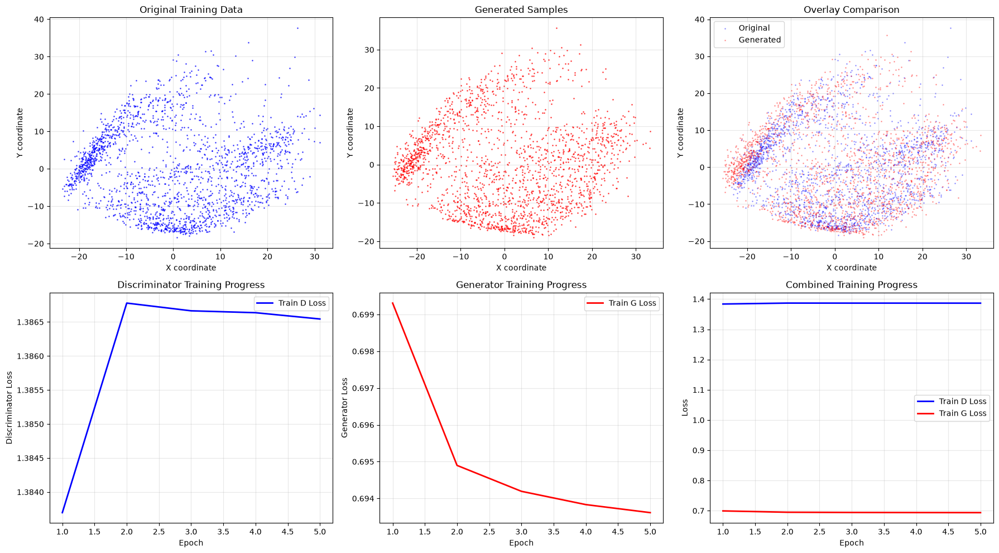

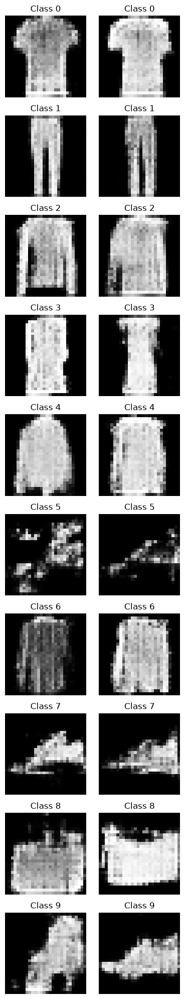

📈 Epoch 5 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3862
   Train G Loss: 0.6936, Val G Loss: 0.6935

📊 Epoch 6/200
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.387054	G_loss: 0.694660
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.386320	G_loss: 0.693747
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.386513	G_loss: 0.693852
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.386643	G_loss: 0.694965
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.385964	G_loss: 0.693509
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.386660	G_loss: 0.696034
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.386414	G_loss: 0.692590
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.386428	G_loss: 0.694593
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.386469	G_loss: 0.692416
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.386343	G_loss: 0.691174
====> Epoch: 6 Train D_loss: 1.3865, Train G_loss: 0.6934
====> Epoch: 6 Val D_loss: 1.3864, Val G_loss: 0.6910
📈 Epoch 6 Summary:
   Train D Loss: 1.3865, Val D Loss: 1.3864
   Train G Loss: 0.6934, Val G Loss: 0

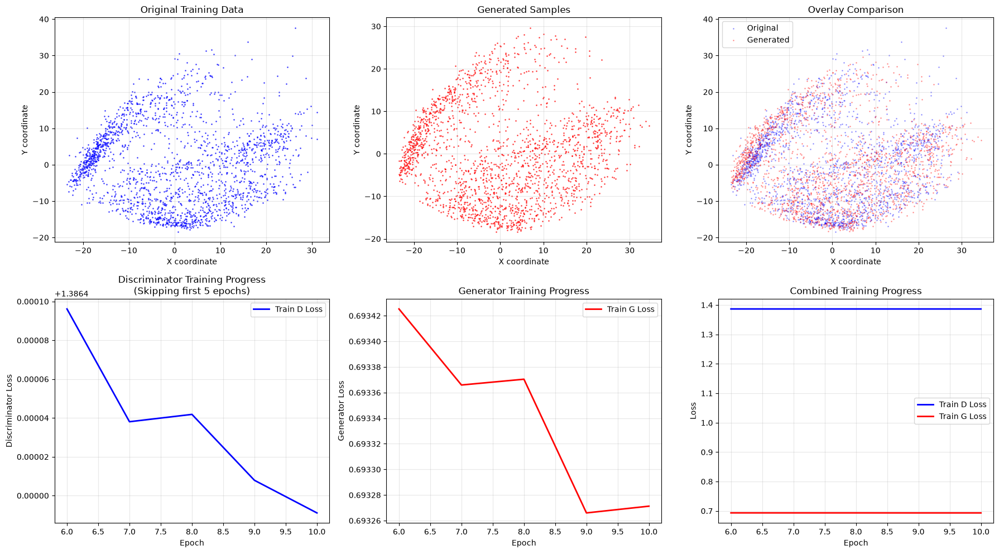

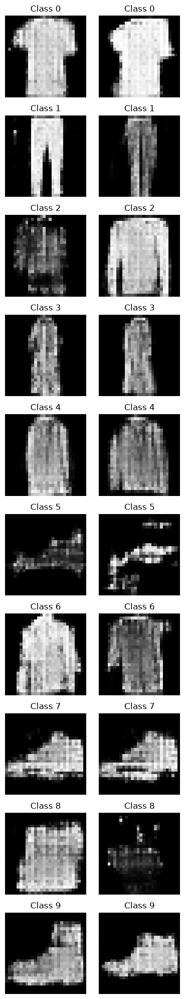

📈 Epoch 10 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3861
   Train G Loss: 0.6933, Val G Loss: 0.6880

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.386168	G_loss: 0.698347
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.386124	G_loss: 0.696429
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.386314	G_loss: 0.692266
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.386455	G_loss: 0.690934
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.386381	G_loss: 0.686779
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.386316	G_loss: 0.695777
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.386230	G_loss: 0.694551
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.386297	G_loss: 0.692507
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.386140	G_loss: 0.695919
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.386549	G_loss: 0.694918
====> Epoch: 11 Train D_loss: 1.3864, Train G_loss: 0.6933
====> Epoch: 11 Val D_loss: 1.3861, Val G_loss: 0.6993
📈 Epoch 11 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3861
   Train G Loss: 0.6933

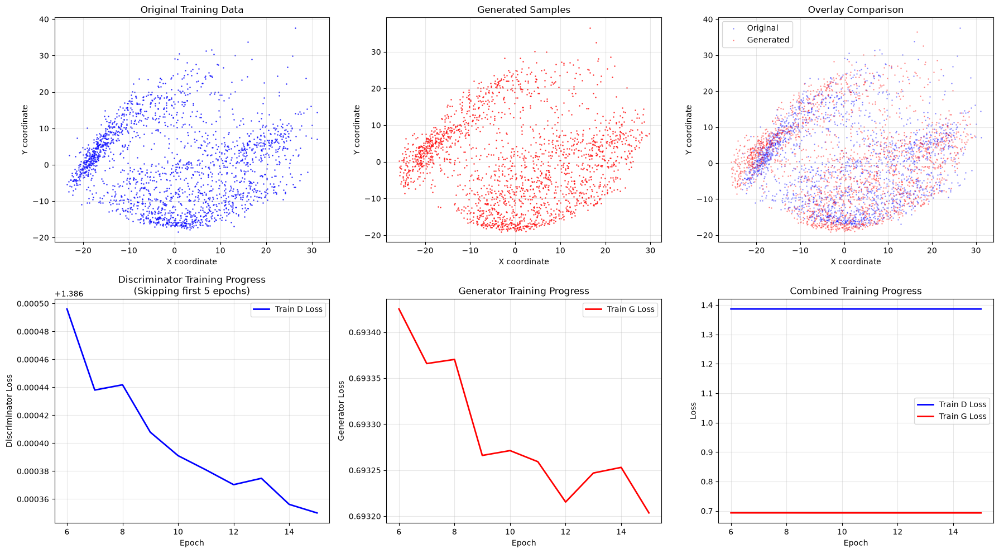

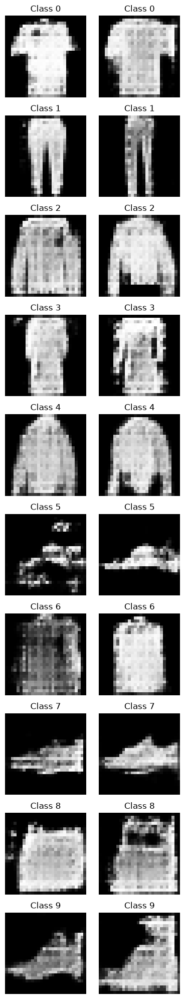

📈 Epoch 15 Summary:
   Train D Loss: 1.3864, Val D Loss: 1.3865
   Train G Loss: 0.6932, Val G Loss: 0.6926

📊 Epoch 16/200
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.386407	G_loss: 0.694847
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.386475	G_loss: 0.693852
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.386481	G_loss: 0.689972
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.386456	G_loss: 0.695931
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.386199	G_loss: 0.691231
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.386240	G_loss: 0.692730
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.386105	G_loss: 0.693807
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.386316	G_loss: 0.692939
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.386354	G_loss: 0.684078
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.386265	G_loss: 0.690119
====> Epoch: 16 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 16 Val D_loss: 1.3864, Val G_loss: 0.6936
📈 Epoch 16 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932

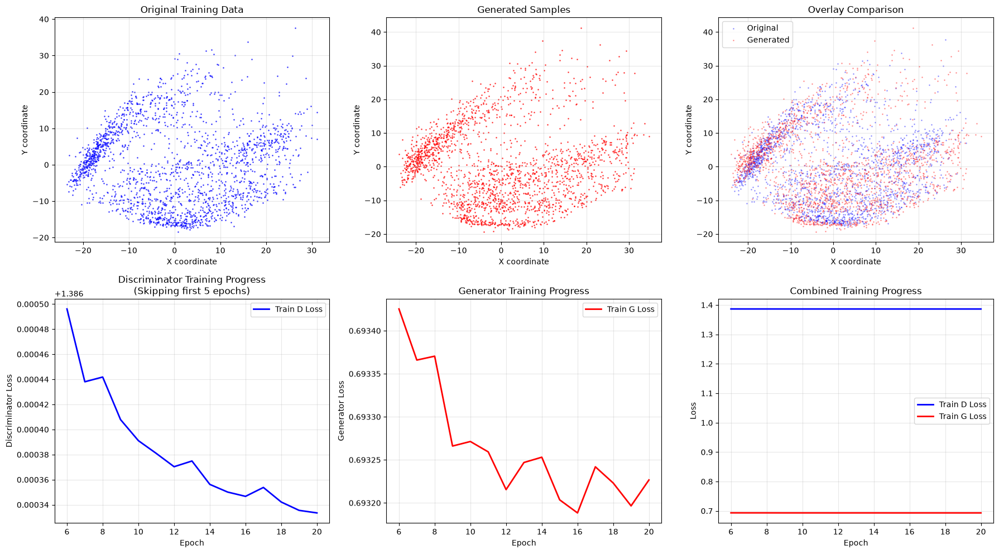

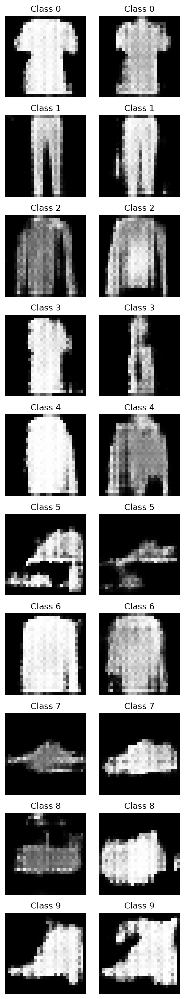

📈 Epoch 20 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6926

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.386314	G_loss: 0.694395
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.386262	G_loss: 0.692764
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.386400	G_loss: 0.691993
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.386512	G_loss: 0.696013
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.386256	G_loss: 0.692905
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.386374	G_loss: 0.690617
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.386366	G_loss: 0.690147
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.386395	G_loss: 0.687941
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.386263	G_loss: 0.692282
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.386346	G_loss: 0.694528
====> Epoch: 21 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 21 Val D_loss: 1.3861, Val G_loss: 0.6897
📈 Epoch 21 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932

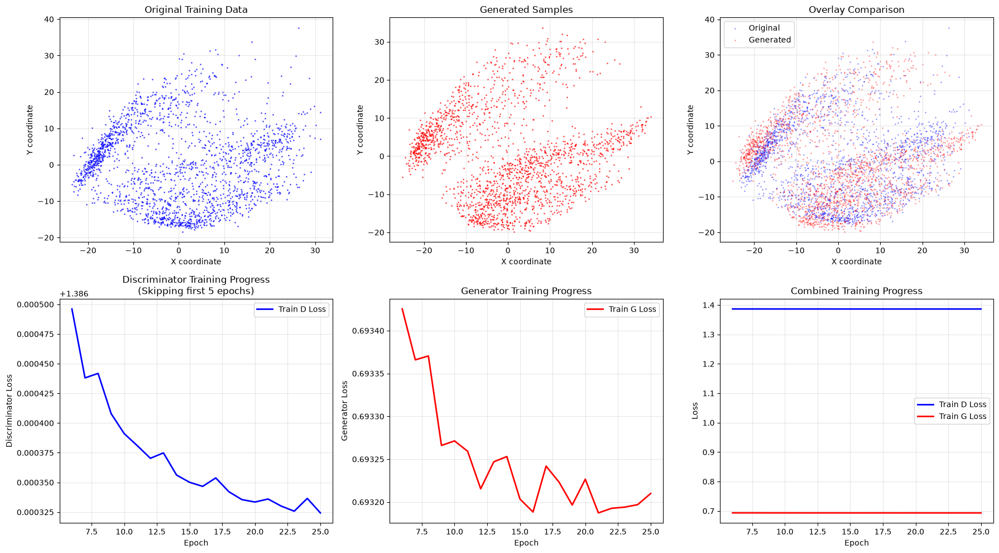

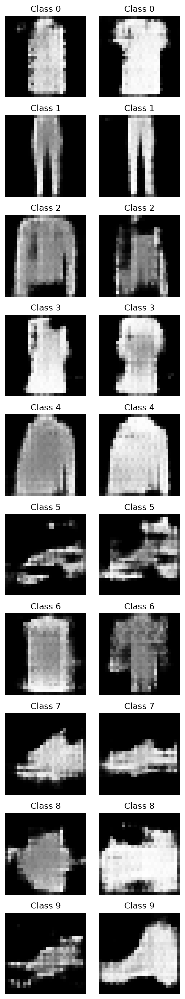

📈 Epoch 25 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6955

📊 Epoch 26/200
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.386278	G_loss: 0.690477
Epoch: 26 [6400/60000 (11%)]	D_loss: 1.386405	G_loss: 0.698110
Epoch: 26 [12800/60000 (21%)]	D_loss: 1.386362	G_loss: 0.689809
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.386440	G_loss: 0.689969
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.386518	G_loss: 0.693589
Epoch: 26 [32000/60000 (53%)]	D_loss: 1.386327	G_loss: 0.691170
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.386358	G_loss: 0.690944
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.386172	G_loss: 0.695116
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.386467	G_loss: 0.692954
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.386485	G_loss: 0.686031
====> Epoch: 26 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 26 Val D_loss: 1.3864, Val G_loss: 0.6919
📈 Epoch 26 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932

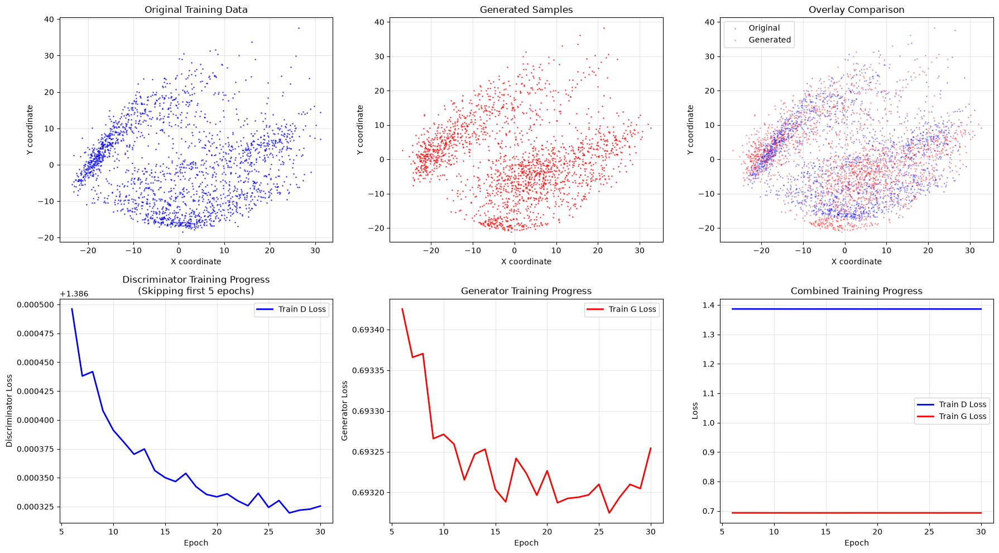

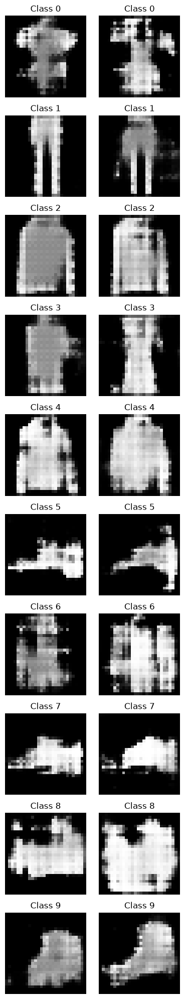

📈 Epoch 30 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train G Loss: 0.6933, Val G Loss: 0.6913

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.386364	G_loss: 0.694190
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.386075	G_loss: 0.692702
Epoch: 31 [12800/60000 (21%)]	D_loss: 1.386258	G_loss: 0.691022
Epoch: 31 [19200/60000 (32%)]	D_loss: 1.387078	G_loss: 0.695889
Epoch: 31 [25600/60000 (43%)]	D_loss: 1.386219	G_loss: 0.692430
Epoch: 31 [32000/60000 (53%)]	D_loss: 1.386390	G_loss: 0.693552
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.386262	G_loss: 0.690801
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.386165	G_loss: 0.695975
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.386285	G_loss: 0.692660
Epoch: 31 [57600/60000 (96%)]	D_loss: 1.386525	G_loss: 0.695319
====> Epoch: 31 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 31 Val D_loss: 1.3859, Val G_loss: 0.6925
📈 Epoch 31 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3859
   Train G Loss: 0.6933

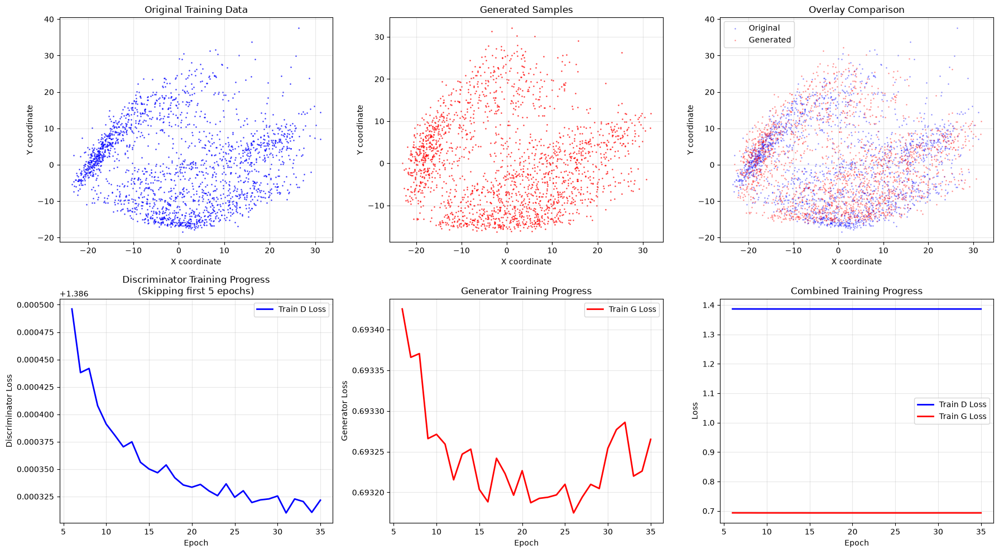

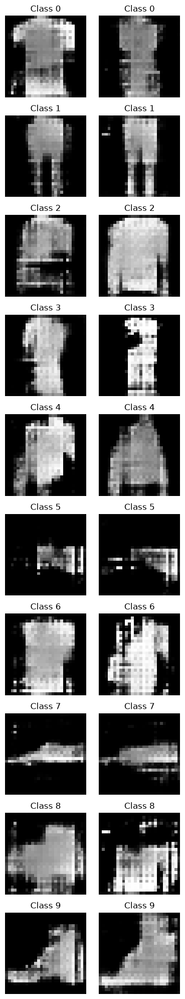

📈 Epoch 35 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3852
   Train G Loss: 0.6933, Val G Loss: 0.6938

📊 Epoch 36/200
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 1.386001	G_loss: 0.691225
Epoch: 36 [6400/60000 (11%)]	D_loss: 1.386664	G_loss: 0.690899
Epoch: 36 [12800/60000 (21%)]	D_loss: 1.386407	G_loss: 0.692896
Epoch: 36 [19200/60000 (32%)]	D_loss: 1.386323	G_loss: 0.693134
Epoch: 36 [25600/60000 (43%)]	D_loss: 1.386254	G_loss: 0.694513
Epoch: 36 [32000/60000 (53%)]	D_loss: 1.386581	G_loss: 0.690257
Epoch: 36 [38400/60000 (64%)]	D_loss: 1.386492	G_loss: 0.694558
Epoch: 36 [44800/60000 (75%)]	D_loss: 1.386084	G_loss: 0.694016
Epoch: 36 [51200/60000 (85%)]	D_loss: 1.386189	G_loss: 0.695170
Epoch: 36 [57600/60000 (96%)]	D_loss: 1.386476	G_loss: 0.692454
====> Epoch: 36 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 36 Val D_loss: 1.3853, Val G_loss: 0.6933
📈 Epoch 36 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3853
   Train G Loss: 0.6932

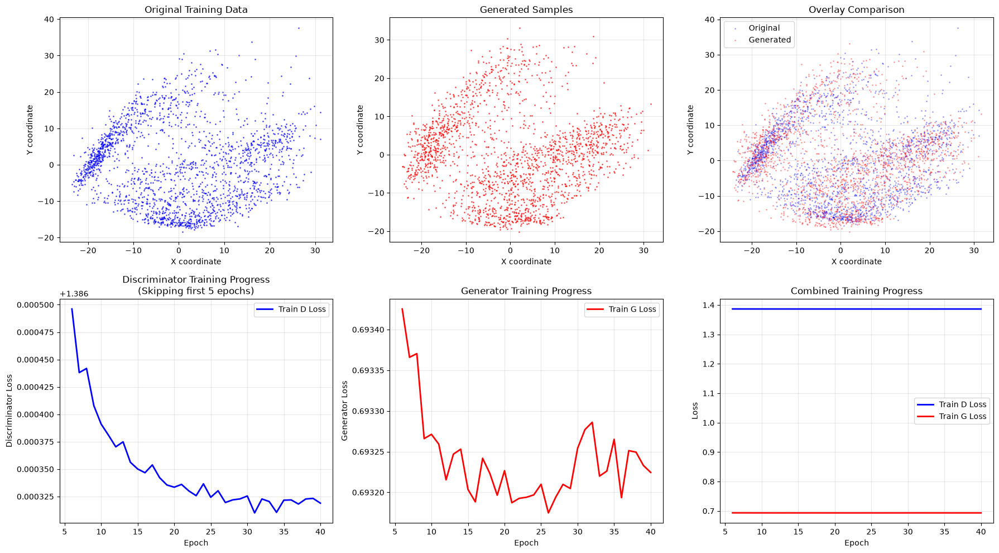

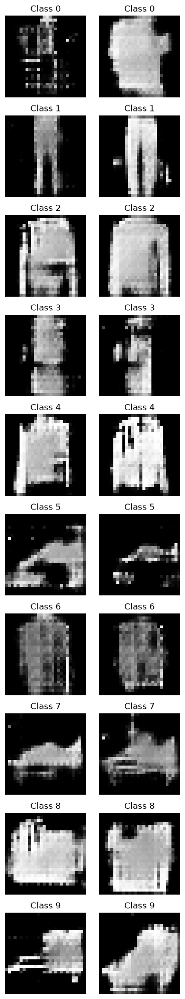

📈 Epoch 40 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3870
   Train G Loss: 0.6932, Val G Loss: 0.6901

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 1.386413	G_loss: 0.695816
Epoch: 41 [6400/60000 (11%)]	D_loss: 1.386441	G_loss: 0.693355
Epoch: 41 [12800/60000 (21%)]	D_loss: 1.386537	G_loss: 0.693043
Epoch: 41 [19200/60000 (32%)]	D_loss: 1.386252	G_loss: 0.695646
Epoch: 41 [25600/60000 (43%)]	D_loss: 1.386231	G_loss: 0.693704
Epoch: 41 [32000/60000 (53%)]	D_loss: 1.386289	G_loss: 0.694192
Epoch: 41 [38400/60000 (64%)]	D_loss: 1.386476	G_loss: 0.691612
Epoch: 41 [44800/60000 (75%)]	D_loss: 1.385676	G_loss: 0.691370
Epoch: 41 [51200/60000 (85%)]	D_loss: 1.386633	G_loss: 0.691623
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.386672	G_loss: 0.697081
====> Epoch: 41 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 41 Val D_loss: 1.3856, Val G_loss: 0.6909
📈 Epoch 41 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3856
   Train G Loss: 0.6932

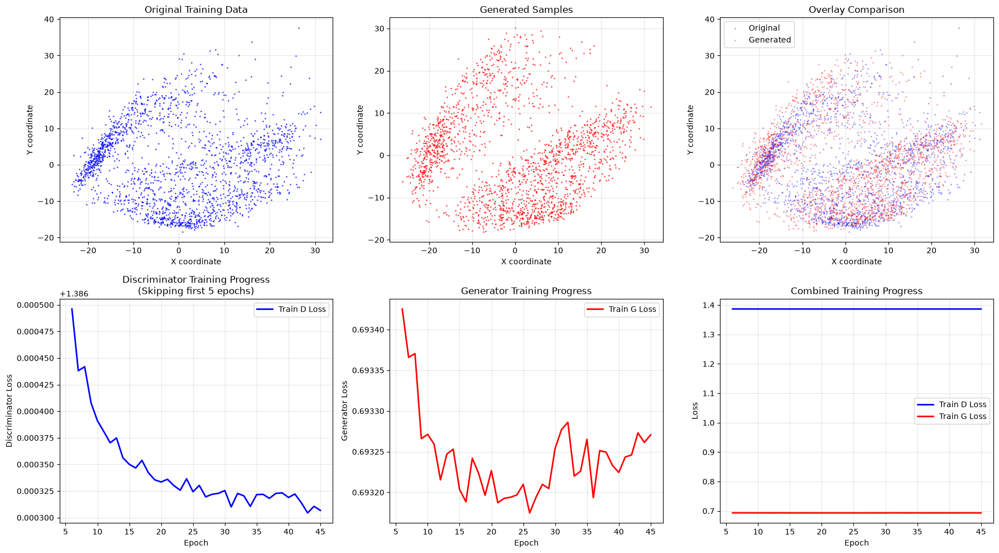

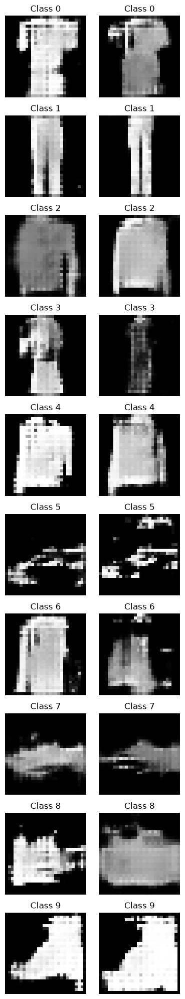

📈 Epoch 45 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3853
   Train G Loss: 0.6933, Val G Loss: 0.6972

📊 Epoch 46/200
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 1.386181	G_loss: 0.692142
Epoch: 46 [6400/60000 (11%)]	D_loss: 1.386282	G_loss: 0.694000
Epoch: 46 [12800/60000 (21%)]	D_loss: 1.385814	G_loss: 0.693916
Epoch: 46 [19200/60000 (32%)]	D_loss: 1.386292	G_loss: 0.694731
Epoch: 46 [25600/60000 (43%)]	D_loss: 1.386337	G_loss: 0.695762
Epoch: 46 [32000/60000 (53%)]	D_loss: 1.386378	G_loss: 0.693308
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.386198	G_loss: 0.692274
Epoch: 46 [44800/60000 (75%)]	D_loss: 1.386084	G_loss: 0.690277
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.386633	G_loss: 0.693662
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.385928	G_loss: 0.694306
====> Epoch: 46 Train D_loss: 1.3863, Train G_loss: 0.6934
====> Epoch: 46 Val D_loss: 1.3856, Val G_loss: 0.6964
📈 Epoch 46 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3856
   Train G Loss: 0.6934

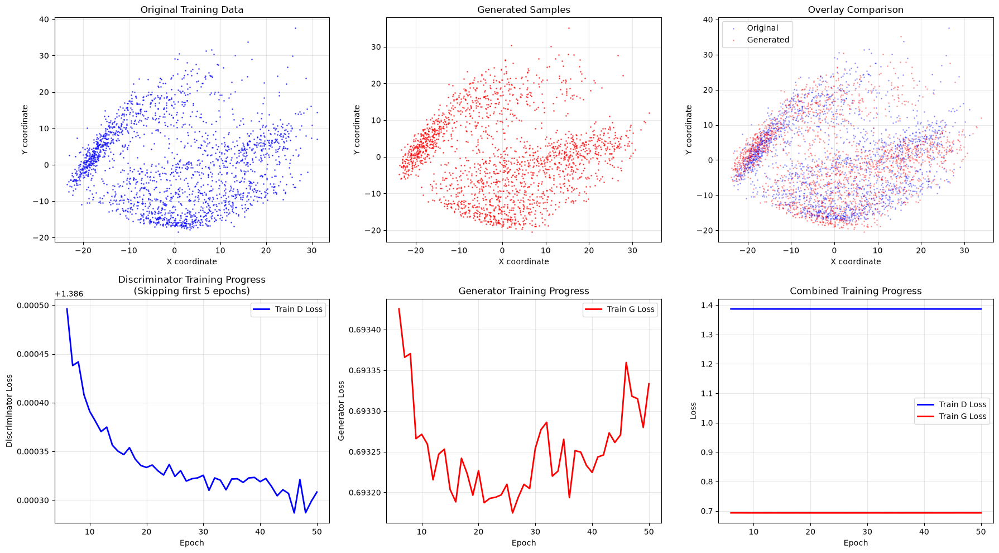

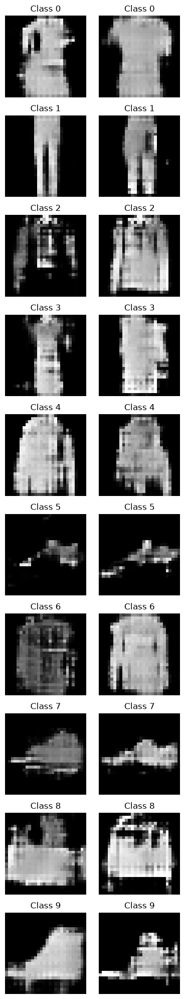

📈 Epoch 50 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3855
   Train G Loss: 0.6933, Val G Loss: 0.6916

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 1.386463	G_loss: 0.696895
Epoch: 51 [6400/60000 (11%)]	D_loss: 1.386155	G_loss: 0.691738
Epoch: 51 [12800/60000 (21%)]	D_loss: 1.386566	G_loss: 0.693747
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.385940	G_loss: 0.691001
Epoch: 51 [25600/60000 (43%)]	D_loss: 1.386636	G_loss: 0.691482
Epoch: 51 [32000/60000 (53%)]	D_loss: 1.386158	G_loss: 0.691819
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.386645	G_loss: 0.692320
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.385856	G_loss: 0.694274
Epoch: 51 [51200/60000 (85%)]	D_loss: 1.386483	G_loss: 0.688759
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.386109	G_loss: 0.691786
====> Epoch: 51 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 51 Val D_loss: 1.3880, Val G_loss: 0.6947
📈 Epoch 51 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3880
   Train G Loss: 0.6933

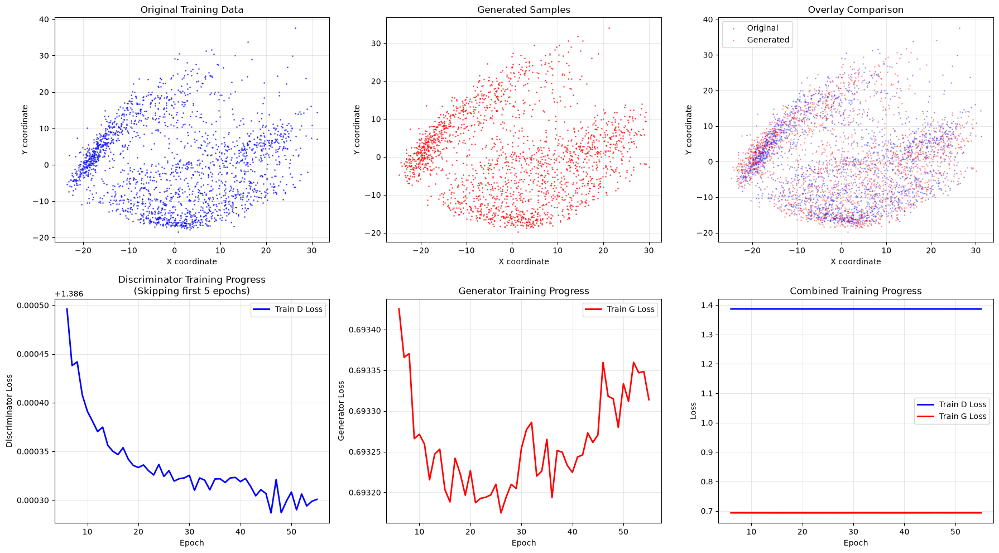

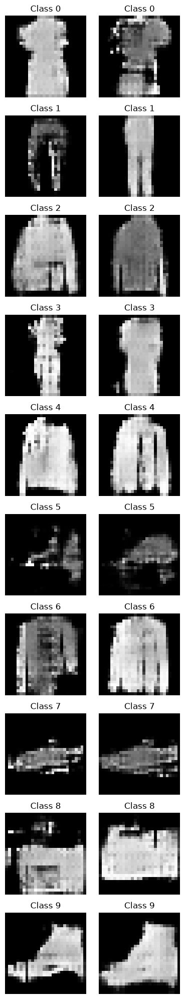

📈 Epoch 55 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3866
   Train G Loss: 0.6933, Val G Loss: 0.6930

📊 Epoch 56/200
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 1.386171	G_loss: 0.692718
Epoch: 56 [6400/60000 (11%)]	D_loss: 1.386652	G_loss: 0.692706
Epoch: 56 [12800/60000 (21%)]	D_loss: 1.386560	G_loss: 0.690391
Epoch: 56 [19200/60000 (32%)]	D_loss: 1.386777	G_loss: 0.693629
Epoch: 56 [25600/60000 (43%)]	D_loss: 1.386693	G_loss: 0.696063
Epoch: 56 [32000/60000 (53%)]	D_loss: 1.386521	G_loss: 0.693552
Epoch: 56 [38400/60000 (64%)]	D_loss: 1.385926	G_loss: 0.692803
Epoch: 56 [44800/60000 (75%)]	D_loss: 1.386421	G_loss: 0.691040
Epoch: 56 [51200/60000 (85%)]	D_loss: 1.386695	G_loss: 0.692222
Epoch: 56 [57600/60000 (96%)]	D_loss: 1.386038	G_loss: 0.690703
====> Epoch: 56 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 56 Val D_loss: 1.3857, Val G_loss: 0.6894
📈 Epoch 56 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3857
   Train G Loss: 0.6933

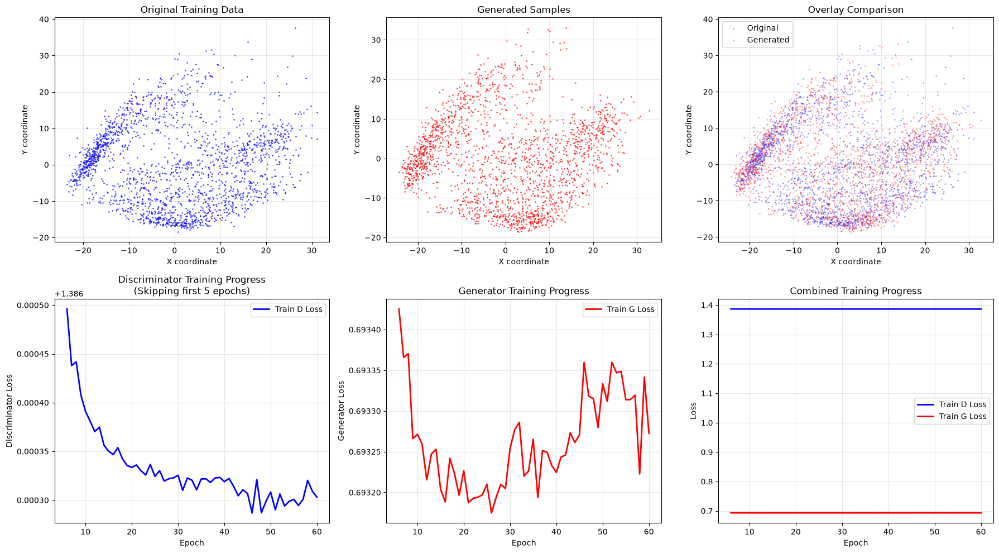

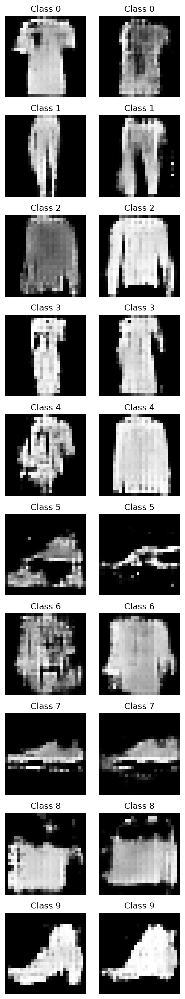

📈 Epoch 60 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3849
   Train G Loss: 0.6933, Val G Loss: 0.6950

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 1.386215	G_loss: 0.695310
Epoch: 61 [6400/60000 (11%)]	D_loss: 1.386659	G_loss: 0.694422
Epoch: 61 [12800/60000 (21%)]	D_loss: 1.386565	G_loss: 0.691469
Epoch: 61 [19200/60000 (32%)]	D_loss: 1.386199	G_loss: 0.693664
Epoch: 61 [25600/60000 (43%)]	D_loss: 1.386775	G_loss: 0.695654
Epoch: 61 [32000/60000 (53%)]	D_loss: 1.385435	G_loss: 0.692712
Epoch: 61 [38400/60000 (64%)]	D_loss: 1.386939	G_loss: 0.690233
Epoch: 61 [44800/60000 (75%)]	D_loss: 1.385818	G_loss: 0.692559
Epoch: 61 [51200/60000 (85%)]	D_loss: 1.386707	G_loss: 0.691935
Epoch: 61 [57600/60000 (96%)]	D_loss: 1.386263	G_loss: 0.692709
====> Epoch: 61 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 61 Val D_loss: 1.3852, Val G_loss: 0.6952
📈 Epoch 61 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3852
   Train G Loss: 0.6933

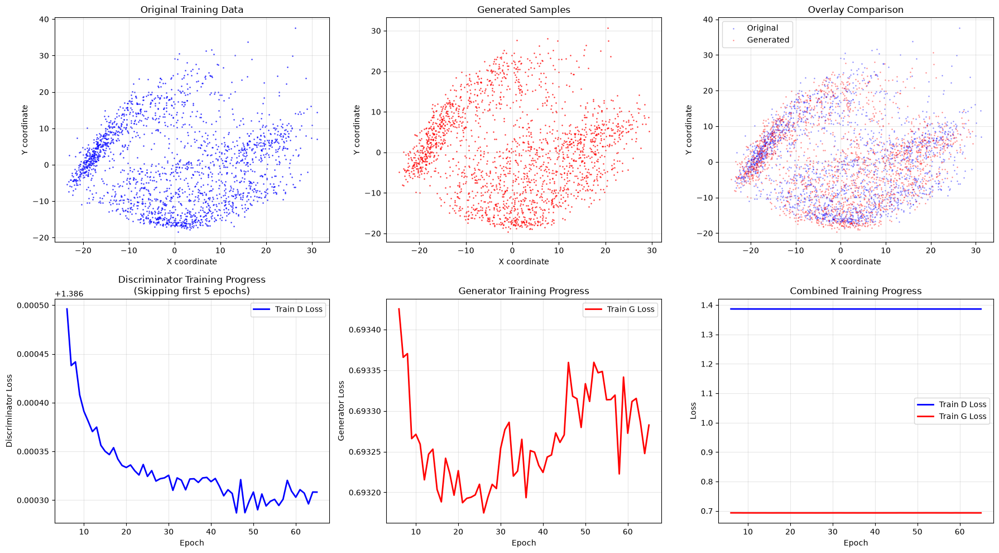

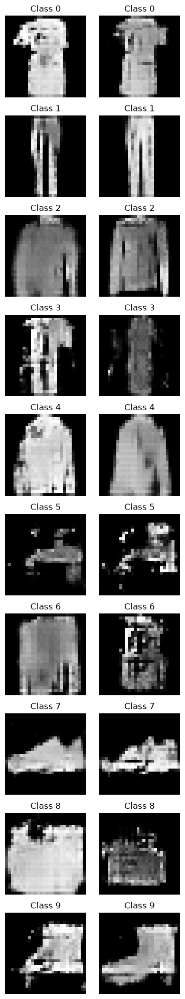

📈 Epoch 65 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3853
   Train G Loss: 0.6933, Val G Loss: 0.6928

📊 Epoch 66/200
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 1.386093	G_loss: 0.692630
Epoch: 66 [6400/60000 (11%)]	D_loss: 1.385973	G_loss: 0.694145
Epoch: 66 [12800/60000 (21%)]	D_loss: 1.386329	G_loss: 0.693933
Epoch: 66 [19200/60000 (32%)]	D_loss: 1.386545	G_loss: 0.695498
Epoch: 66 [25600/60000 (43%)]	D_loss: 1.386110	G_loss: 0.692253
Epoch: 66 [32000/60000 (53%)]	D_loss: 1.386244	G_loss: 0.691131
Epoch: 66 [38400/60000 (64%)]	D_loss: 1.386219	G_loss: 0.693164
Epoch: 66 [44800/60000 (75%)]	D_loss: 1.386131	G_loss: 0.693133
Epoch: 66 [51200/60000 (85%)]	D_loss: 1.386351	G_loss: 0.694531
Epoch: 66 [57600/60000 (96%)]	D_loss: 1.386661	G_loss: 0.692000
====> Epoch: 66 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 66 Val D_loss: 1.3855, Val G_loss: 0.6963
📈 Epoch 66 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3855
   Train G Loss: 0.6933

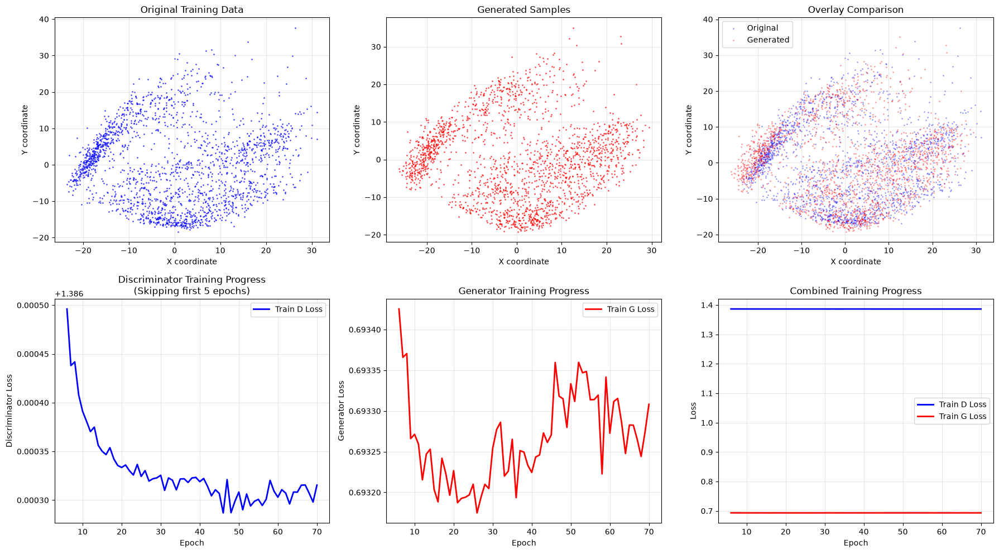

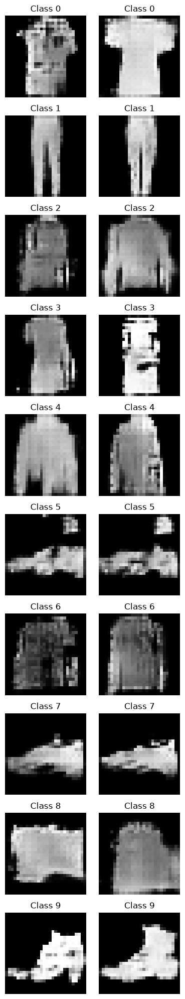

📈 Epoch 70 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6933, Val G Loss: 0.6920

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 1.386209	G_loss: 0.696116
Epoch: 71 [6400/60000 (11%)]	D_loss: 1.386343	G_loss: 0.691911
Epoch: 71 [12800/60000 (21%)]	D_loss: 1.386291	G_loss: 0.694240
Epoch: 71 [19200/60000 (32%)]	D_loss: 1.386011	G_loss: 0.693918
Epoch: 71 [25600/60000 (43%)]	D_loss: 1.386757	G_loss: 0.692633
Epoch: 71 [32000/60000 (53%)]	D_loss: 1.386044	G_loss: 0.694708
Epoch: 71 [38400/60000 (64%)]	D_loss: 1.386477	G_loss: 0.692697
Epoch: 71 [44800/60000 (75%)]	D_loss: 1.386513	G_loss: 0.690877
Epoch: 71 [51200/60000 (85%)]	D_loss: 1.386693	G_loss: 0.691799
Epoch: 71 [57600/60000 (96%)]	D_loss: 1.386869	G_loss: 0.692073
====> Epoch: 71 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 71 Val D_loss: 1.3860, Val G_loss: 0.6917
📈 Epoch 71 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3860
   Train G Loss: 0.6933

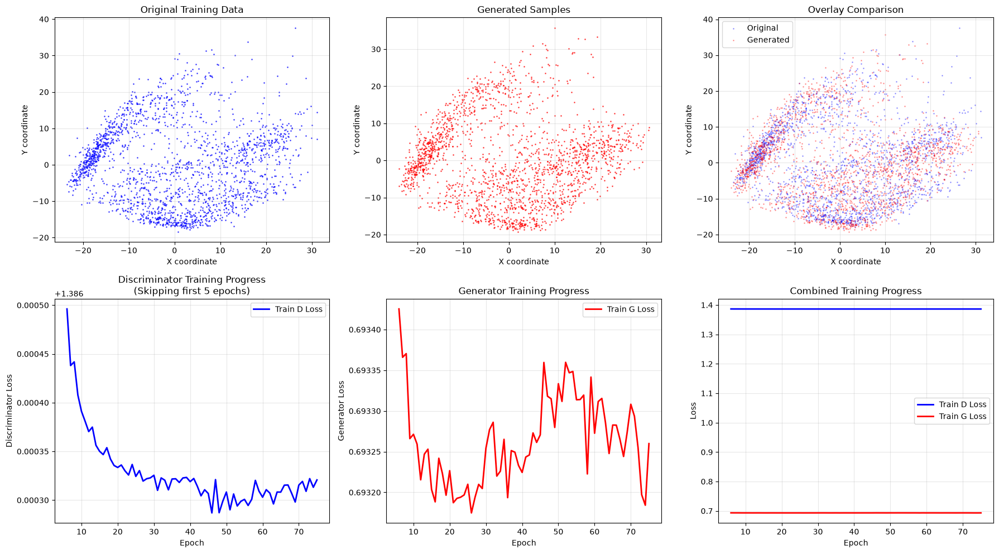

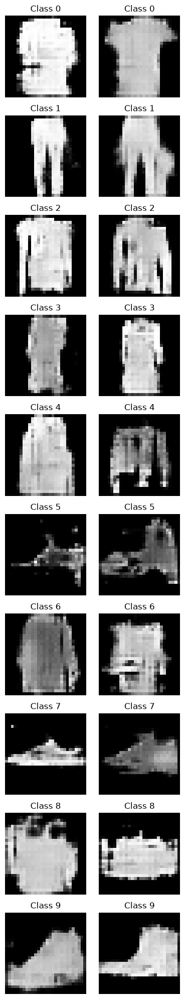

📈 Epoch 75 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3855
   Train G Loss: 0.6933, Val G Loss: 0.6905

📊 Epoch 76/200
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 1.386163	G_loss: 0.695667
Epoch: 76 [6400/60000 (11%)]	D_loss: 1.386407	G_loss: 0.694433
Epoch: 76 [12800/60000 (21%)]	D_loss: 1.385762	G_loss: 0.692229
Epoch: 76 [19200/60000 (32%)]	D_loss: 1.386457	G_loss: 0.696260
Epoch: 76 [25600/60000 (43%)]	D_loss: 1.386308	G_loss: 0.694574
Epoch: 76 [32000/60000 (53%)]	D_loss: 1.386484	G_loss: 0.690985
Epoch: 76 [38400/60000 (64%)]	D_loss: 1.386436	G_loss: 0.693013
Epoch: 76 [44800/60000 (75%)]	D_loss: 1.386474	G_loss: 0.692250
Epoch: 76 [51200/60000 (85%)]	D_loss: 1.386331	G_loss: 0.692018
Epoch: 76 [57600/60000 (96%)]	D_loss: 1.386467	G_loss: 0.690099
====> Epoch: 76 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 76 Val D_loss: 1.3864, Val G_loss: 0.6931
📈 Epoch 76 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932

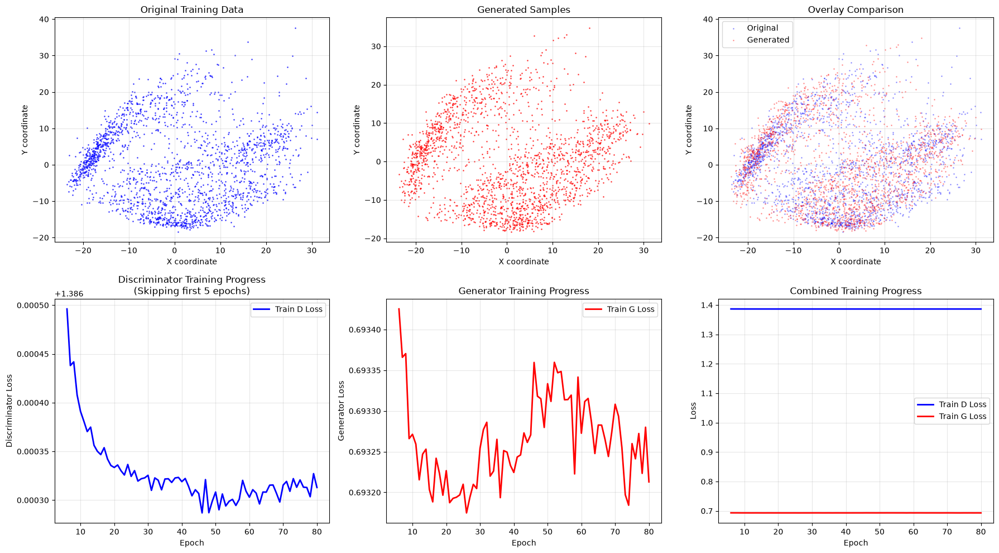

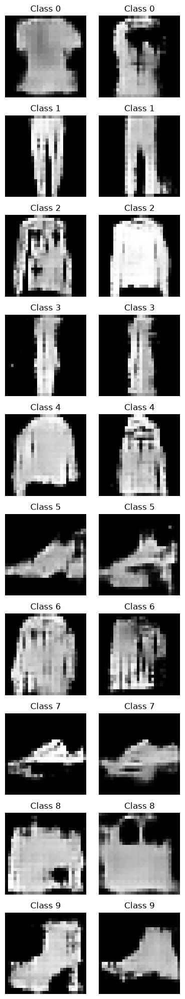

📈 Epoch 80 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6918

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 1.386199	G_loss: 0.695602
Epoch: 81 [6400/60000 (11%)]	D_loss: 1.386432	G_loss: 0.693451
Epoch: 81 [12800/60000 (21%)]	D_loss: 1.386329	G_loss: 0.692225
Epoch: 81 [19200/60000 (32%)]	D_loss: 1.386455	G_loss: 0.691628
Epoch: 81 [25600/60000 (43%)]	D_loss: 1.386202	G_loss: 0.695534
Epoch: 81 [32000/60000 (53%)]	D_loss: 1.386454	G_loss: 0.692596
Epoch: 81 [38400/60000 (64%)]	D_loss: 1.386351	G_loss: 0.692865
Epoch: 81 [44800/60000 (75%)]	D_loss: 1.386527	G_loss: 0.688762
Epoch: 81 [51200/60000 (85%)]	D_loss: 1.386312	G_loss: 0.697125
Epoch: 81 [57600/60000 (96%)]	D_loss: 1.386227	G_loss: 0.691047
====> Epoch: 81 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 81 Val D_loss: 1.3862, Val G_loss: 0.6921
📈 Epoch 81 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932

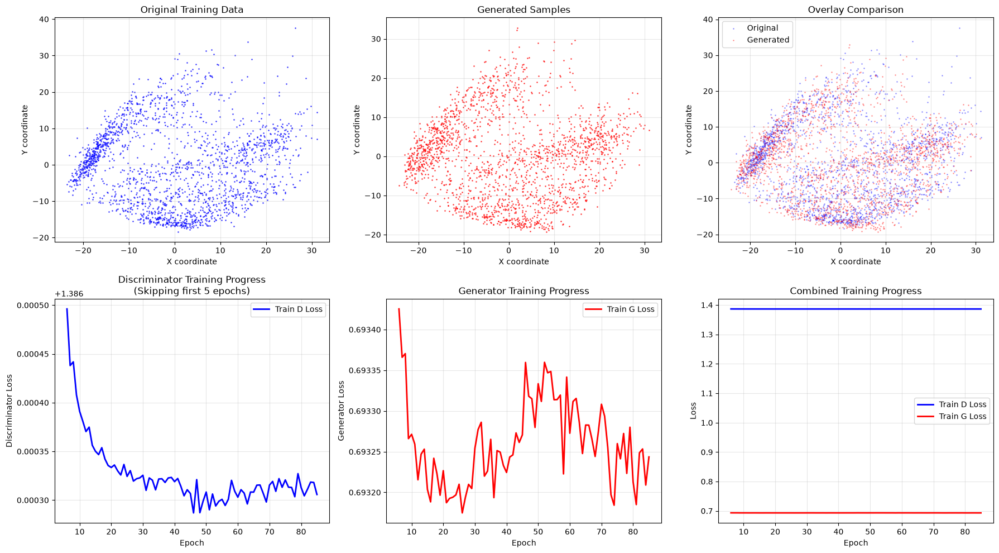

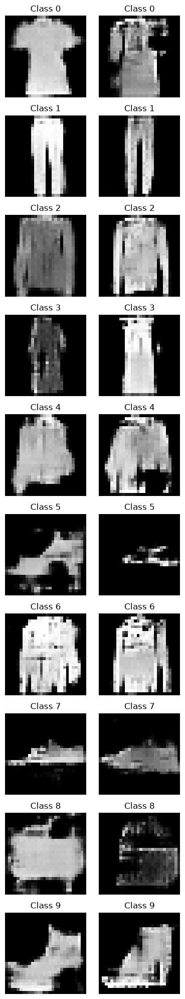

📈 Epoch 85 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6924

📊 Epoch 86/200
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 1.386256	G_loss: 0.693497
Epoch: 86 [6400/60000 (11%)]	D_loss: 1.386209	G_loss: 0.693430
Epoch: 86 [12800/60000 (21%)]	D_loss: 1.386286	G_loss: 0.692968
Epoch: 86 [19200/60000 (32%)]	D_loss: 1.386290	G_loss: 0.694519
Epoch: 86 [25600/60000 (43%)]	D_loss: 1.386239	G_loss: 0.694329
Epoch: 86 [32000/60000 (53%)]	D_loss: 1.386262	G_loss: 0.691880
Epoch: 86 [38400/60000 (64%)]	D_loss: 1.386265	G_loss: 0.693255
Epoch: 86 [44800/60000 (75%)]	D_loss: 1.386303	G_loss: 0.692385
Epoch: 86 [51200/60000 (85%)]	D_loss: 1.386292	G_loss: 0.692288
Epoch: 86 [57600/60000 (96%)]	D_loss: 1.386209	G_loss: 0.693505
====> Epoch: 86 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 86 Val D_loss: 1.3863, Val G_loss: 0.6914
📈 Epoch 86 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932

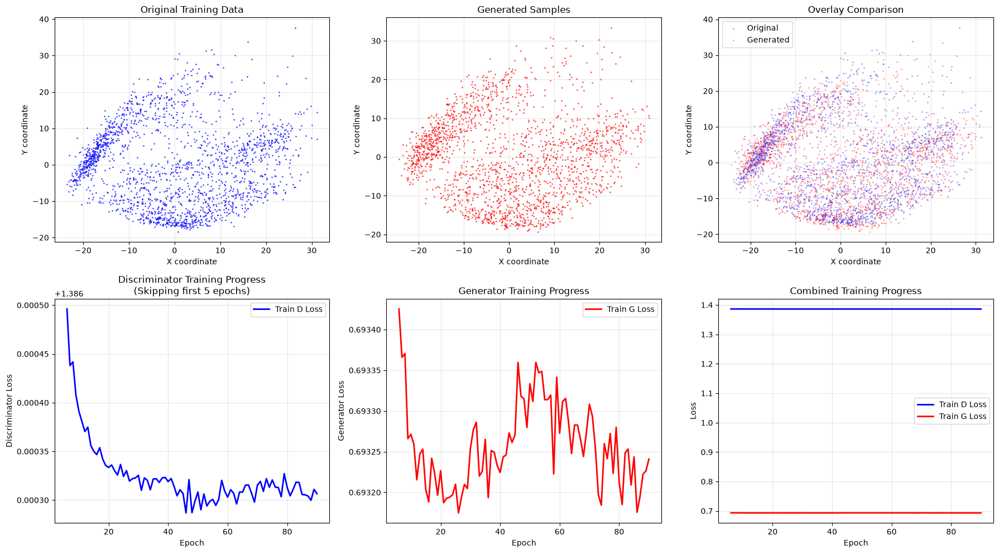

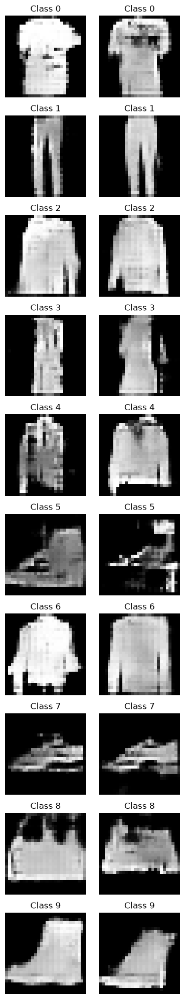

📈 Epoch 90 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3869
   Train G Loss: 0.6932, Val G Loss: 0.6929

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 1.386416	G_loss: 0.690587
Epoch: 91 [6400/60000 (11%)]	D_loss: 1.386119	G_loss: 0.694573
Epoch: 91 [12800/60000 (21%)]	D_loss: 1.386643	G_loss: 0.692692
Epoch: 91 [19200/60000 (32%)]	D_loss: 1.386409	G_loss: 0.692053
Epoch: 91 [25600/60000 (43%)]	D_loss: 1.386428	G_loss: 0.695411
Epoch: 91 [32000/60000 (53%)]	D_loss: 1.386543	G_loss: 0.693342
Epoch: 91 [38400/60000 (64%)]	D_loss: 1.386070	G_loss: 0.693609
Epoch: 91 [44800/60000 (75%)]	D_loss: 1.386471	G_loss: 0.694587
Epoch: 91 [51200/60000 (85%)]	D_loss: 1.386367	G_loss: 0.691595
Epoch: 91 [57600/60000 (96%)]	D_loss: 1.386526	G_loss: 0.693576
====> Epoch: 91 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 91 Val D_loss: 1.3865, Val G_loss: 0.6953
📈 Epoch 91 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train G Loss: 0.6933

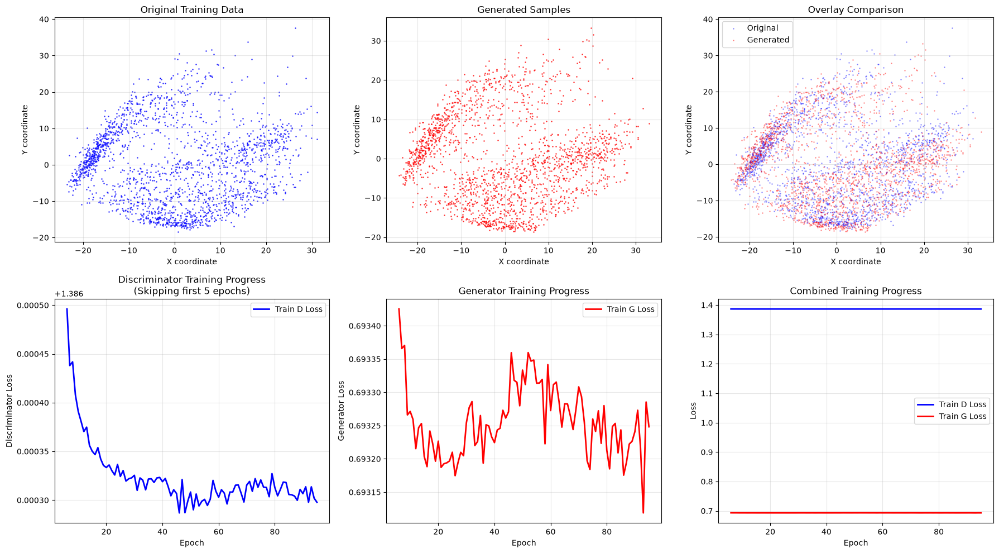

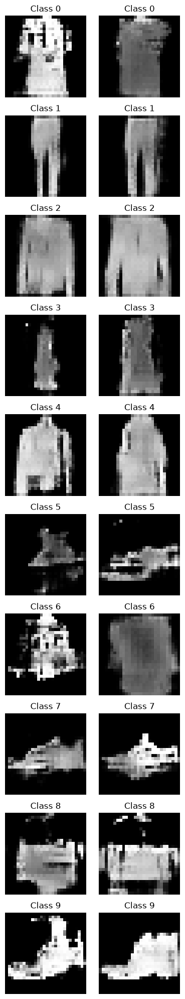

📈 Epoch 95 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932, Val G Loss: 0.6920

📊 Epoch 96/200
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 1.386362	G_loss: 0.693297
Epoch: 96 [6400/60000 (11%)]	D_loss: 1.386319	G_loss: 0.693449
Epoch: 96 [12800/60000 (21%)]	D_loss: 1.386374	G_loss: 0.693745
Epoch: 96 [19200/60000 (32%)]	D_loss: 1.386293	G_loss: 0.692777
Epoch: 96 [25600/60000 (43%)]	D_loss: 1.386351	G_loss: 0.692589
Epoch: 96 [32000/60000 (53%)]	D_loss: 1.386279	G_loss: 0.692642
Epoch: 96 [38400/60000 (64%)]	D_loss: 1.386195	G_loss: 0.693354
Epoch: 96 [44800/60000 (75%)]	D_loss: 1.386255	G_loss: 0.694116
Epoch: 96 [51200/60000 (85%)]	D_loss: 1.386395	G_loss: 0.692365
Epoch: 96 [57600/60000 (96%)]	D_loss: 1.386369	G_loss: 0.692901
====> Epoch: 96 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 96 Val D_loss: 1.3861, Val G_loss: 0.6939
📈 Epoch 96 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932

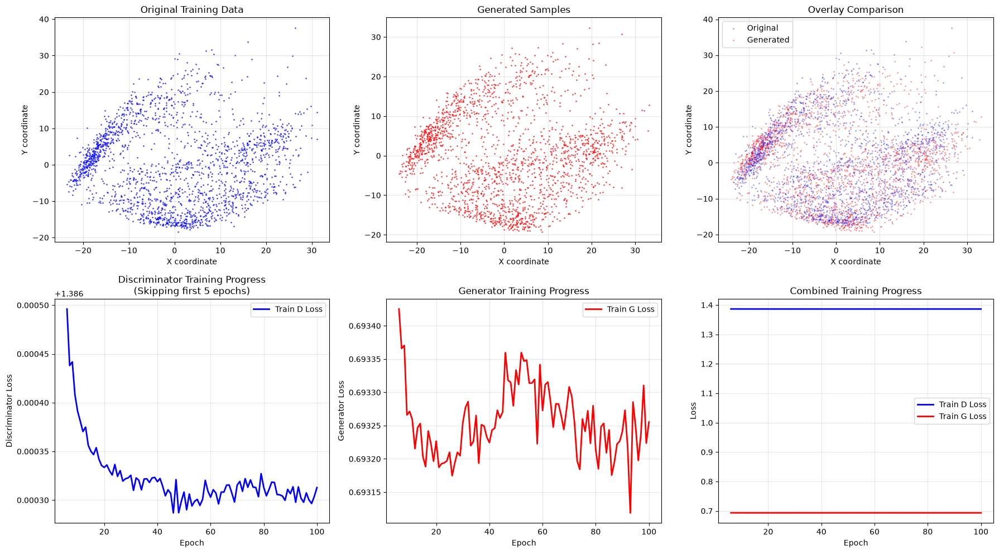

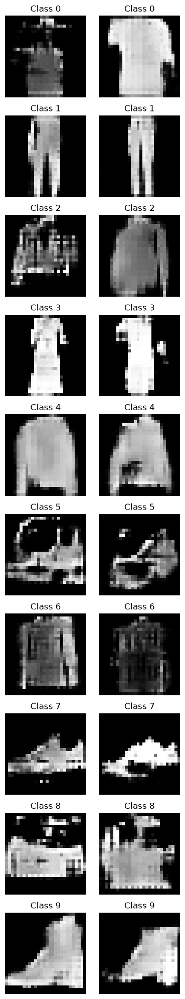

📈 Epoch 100 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3867
   Train G Loss: 0.6933, Val G Loss: 0.6921

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/60000 (0%)]	D_loss: 1.386455	G_loss: 0.691775
Epoch: 101 [6400/60000 (11%)]	D_loss: 1.386294	G_loss: 0.694939
Epoch: 101 [12800/60000 (21%)]	D_loss: 1.386376	G_loss: 0.694275
Epoch: 101 [19200/60000 (32%)]	D_loss: 1.386215	G_loss: 0.693952
Epoch: 101 [25600/60000 (43%)]	D_loss: 1.386167	G_loss: 0.693303
Epoch: 101 [32000/60000 (53%)]	D_loss: 1.386240	G_loss: 0.693924
Epoch: 101 [38400/60000 (64%)]	D_loss: 1.386210	G_loss: 0.693138
Epoch: 101 [44800/60000 (75%)]	D_loss: 1.386004	G_loss: 0.693588
Epoch: 101 [51200/60000 (85%)]	D_loss: 1.386200	G_loss: 0.693030
Epoch: 101 [57600/60000 (96%)]	D_loss: 1.386186	G_loss: 0.694031
====> Epoch: 101 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 101 Val D_loss: 1.3870, Val G_loss: 0.6908
📈 Epoch 101 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3870
   Train

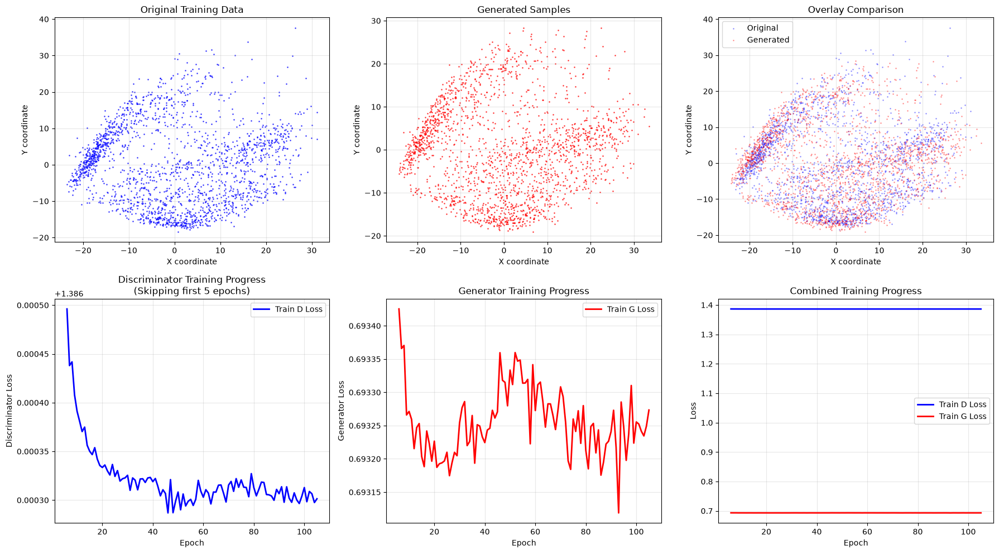

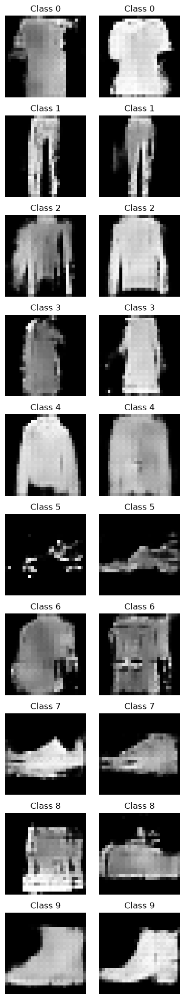

📈 Epoch 105 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3872
   Train G Loss: 0.6933, Val G Loss: 0.6931

📊 Epoch 106/200
----------------------------------------
Epoch: 106 [0/60000 (0%)]	D_loss: 1.386385	G_loss: 0.692758
Epoch: 106 [6400/60000 (11%)]	D_loss: 1.386332	G_loss: 0.693103
Epoch: 106 [12800/60000 (21%)]	D_loss: 1.386314	G_loss: 0.692022
Epoch: 106 [19200/60000 (32%)]	D_loss: 1.386334	G_loss: 0.691499
Epoch: 106 [25600/60000 (43%)]	D_loss: 1.386233	G_loss: 0.694102
Epoch: 106 [32000/60000 (53%)]	D_loss: 1.386377	G_loss: 0.693499
Epoch: 106 [38400/60000 (64%)]	D_loss: 1.386290	G_loss: 0.691672
Epoch: 106 [44800/60000 (75%)]	D_loss: 1.386266	G_loss: 0.693997
Epoch: 106 [51200/60000 (85%)]	D_loss: 1.385870	G_loss: 0.692292
Epoch: 106 [57600/60000 (96%)]	D_loss: 1.386412	G_loss: 0.693671
====> Epoch: 106 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 106 Val D_loss: 1.3865, Val G_loss: 0.6913
📈 Epoch 106 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3865
   Train

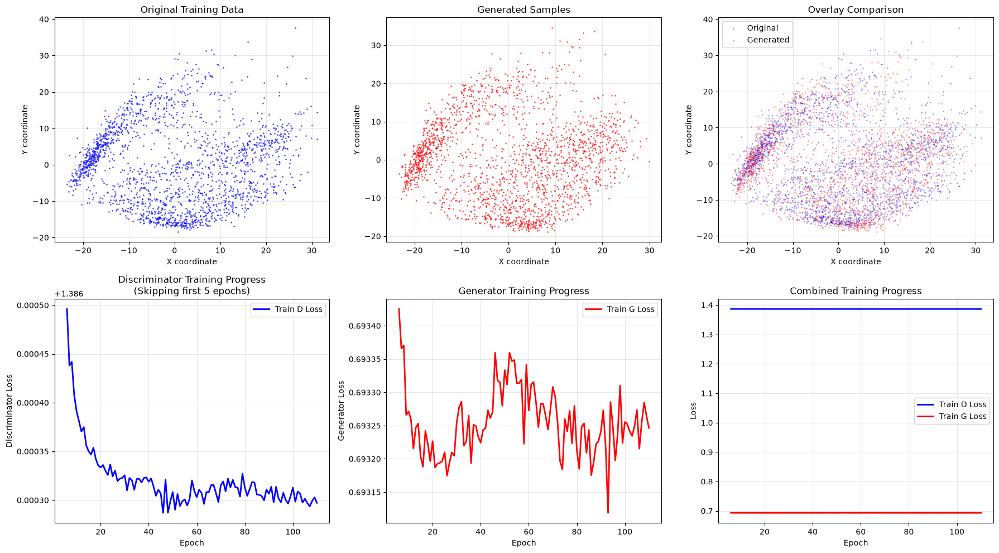

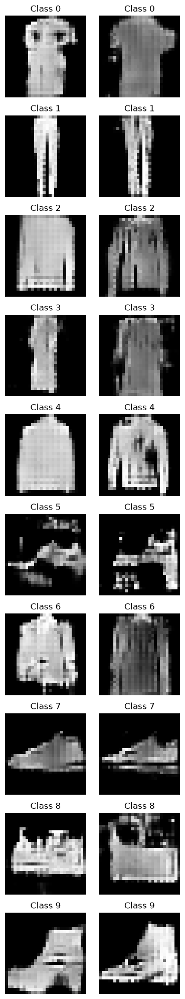

📈 Epoch 110 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3869
   Train G Loss: 0.6932, Val G Loss: 0.6967

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/60000 (0%)]	D_loss: 1.386293	G_loss: 0.692906
Epoch: 111 [6400/60000 (11%)]	D_loss: 1.386094	G_loss: 0.692655
Epoch: 111 [12800/60000 (21%)]	D_loss: 1.386664	G_loss: 0.693076
Epoch: 111 [19200/60000 (32%)]	D_loss: 1.386349	G_loss: 0.692347
Epoch: 111 [25600/60000 (43%)]	D_loss: 1.386233	G_loss: 0.693673
Epoch: 111 [32000/60000 (53%)]	D_loss: 1.386757	G_loss: 0.692454
Epoch: 111 [38400/60000 (64%)]	D_loss: 1.386368	G_loss: 0.693748
Epoch: 111 [44800/60000 (75%)]	D_loss: 1.386120	G_loss: 0.692650
Epoch: 111 [51200/60000 (85%)]	D_loss: 1.386359	G_loss: 0.693419
Epoch: 111 [57600/60000 (96%)]	D_loss: 1.386503	G_loss: 0.695245
====> Epoch: 111 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 111 Val D_loss: 1.3859, Val G_loss: 0.6923
📈 Epoch 111 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3859
   Train

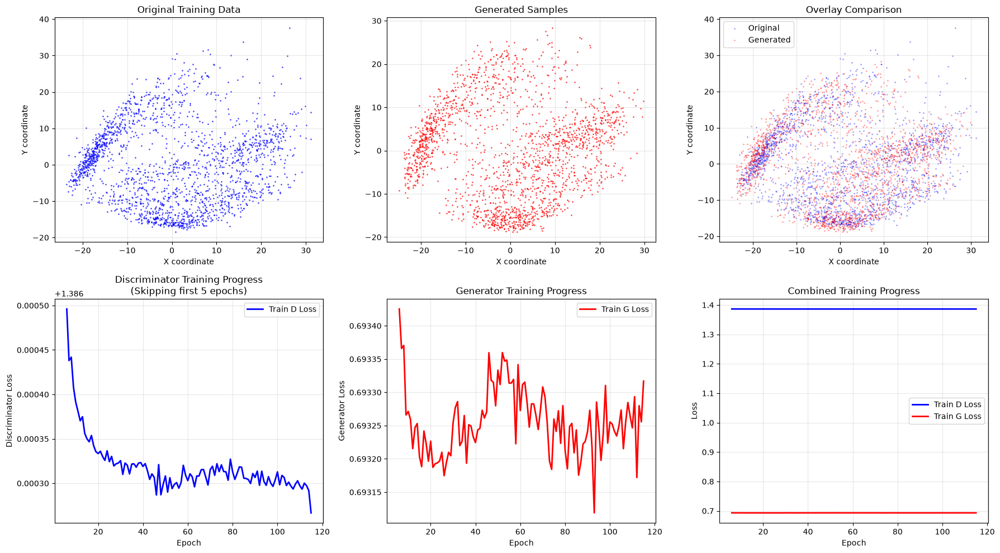

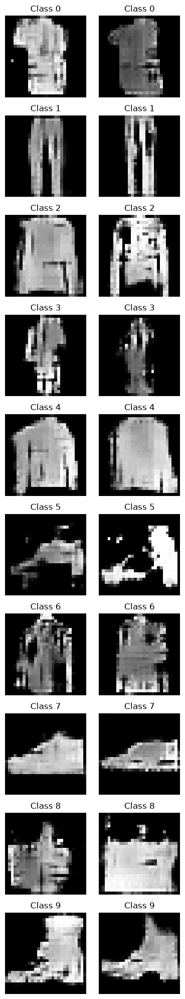

📈 Epoch 115 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6933, Val G Loss: 0.6925

📊 Epoch 116/200
----------------------------------------
Epoch: 116 [0/60000 (0%)]	D_loss: 1.385904	G_loss: 0.694751
Epoch: 116 [6400/60000 (11%)]	D_loss: 1.386428	G_loss: 0.694572
Epoch: 116 [12800/60000 (21%)]	D_loss: 1.385895	G_loss: 0.693342
Epoch: 116 [19200/60000 (32%)]	D_loss: 1.386440	G_loss: 0.692308
Epoch: 116 [25600/60000 (43%)]	D_loss: 1.386438	G_loss: 0.691304
Epoch: 116 [32000/60000 (53%)]	D_loss: 1.386561	G_loss: 0.692217
Epoch: 116 [38400/60000 (64%)]	D_loss: 1.386181	G_loss: 0.694535
Epoch: 116 [44800/60000 (75%)]	D_loss: 1.386295	G_loss: 0.692630
Epoch: 116 [51200/60000 (85%)]	D_loss: 1.386483	G_loss: 0.693886
Epoch: 116 [57600/60000 (96%)]	D_loss: 1.385933	G_loss: 0.693524
====> Epoch: 116 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 116 Val D_loss: 1.3862, Val G_loss: 0.6940
📈 Epoch 116 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train

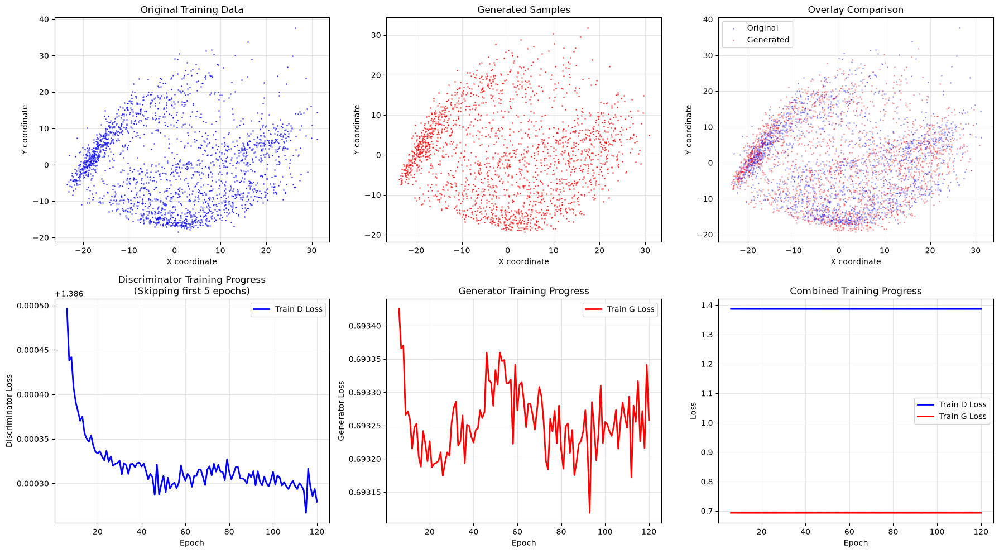

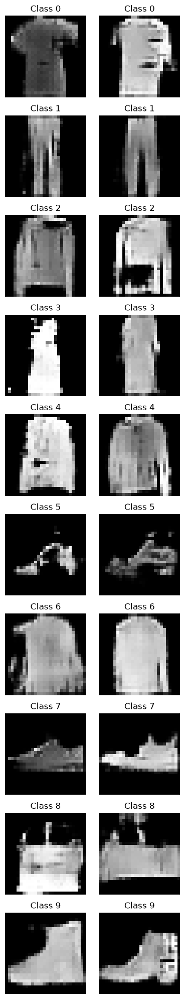

📈 Epoch 120 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3856
   Train G Loss: 0.6933, Val G Loss: 0.6948

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/60000 (0%)]	D_loss: 1.386305	G_loss: 0.692528
Epoch: 121 [6400/60000 (11%)]	D_loss: 1.386260	G_loss: 0.692234
Epoch: 121 [12800/60000 (21%)]	D_loss: 1.386116	G_loss: 0.695674
Epoch: 121 [19200/60000 (32%)]	D_loss: 1.385820	G_loss: 0.691720
Epoch: 121 [25600/60000 (43%)]	D_loss: 1.386213	G_loss: 0.694014
Epoch: 121 [32000/60000 (53%)]	D_loss: 1.386535	G_loss: 0.693806
Epoch: 121 [38400/60000 (64%)]	D_loss: 1.386447	G_loss: 0.690791
Epoch: 121 [44800/60000 (75%)]	D_loss: 1.386431	G_loss: 0.693095
Epoch: 121 [51200/60000 (85%)]	D_loss: 1.386762	G_loss: 0.693873
Epoch: 121 [57600/60000 (96%)]	D_loss: 1.386225	G_loss: 0.692901
====> Epoch: 121 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 121 Val D_loss: 1.3853, Val G_loss: 0.6940
📈 Epoch 121 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3853
   Train

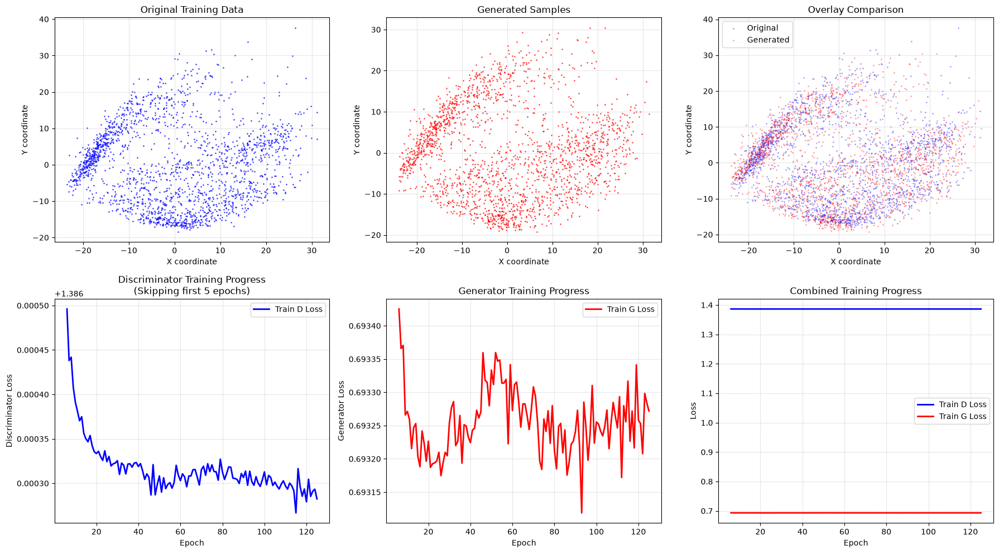

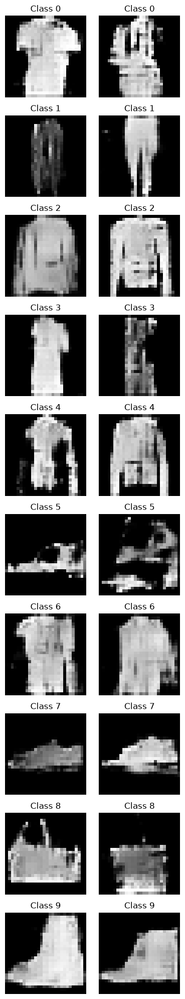

📈 Epoch 125 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6933, Val G Loss: 0.6945

📊 Epoch 126/200
----------------------------------------
Epoch: 126 [0/60000 (0%)]	D_loss: 1.386090	G_loss: 0.693882
Epoch: 126 [6400/60000 (11%)]	D_loss: 1.386026	G_loss: 0.691053
Epoch: 126 [12800/60000 (21%)]	D_loss: 1.386621	G_loss: 0.694406
Epoch: 126 [19200/60000 (32%)]	D_loss: 1.386169	G_loss: 0.692085
Epoch: 126 [25600/60000 (43%)]	D_loss: 1.386139	G_loss: 0.692642
Epoch: 126 [32000/60000 (53%)]	D_loss: 1.386511	G_loss: 0.693304
Epoch: 126 [38400/60000 (64%)]	D_loss: 1.386672	G_loss: 0.692321
Epoch: 126 [44800/60000 (75%)]	D_loss: 1.385994	G_loss: 0.693525
Epoch: 126 [51200/60000 (85%)]	D_loss: 1.386938	G_loss: 0.694977
Epoch: 126 [57600/60000 (96%)]	D_loss: 1.386408	G_loss: 0.691684
====> Epoch: 126 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 126 Val D_loss: 1.3853, Val G_loss: 0.6949
📈 Epoch 126 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3853
   Train

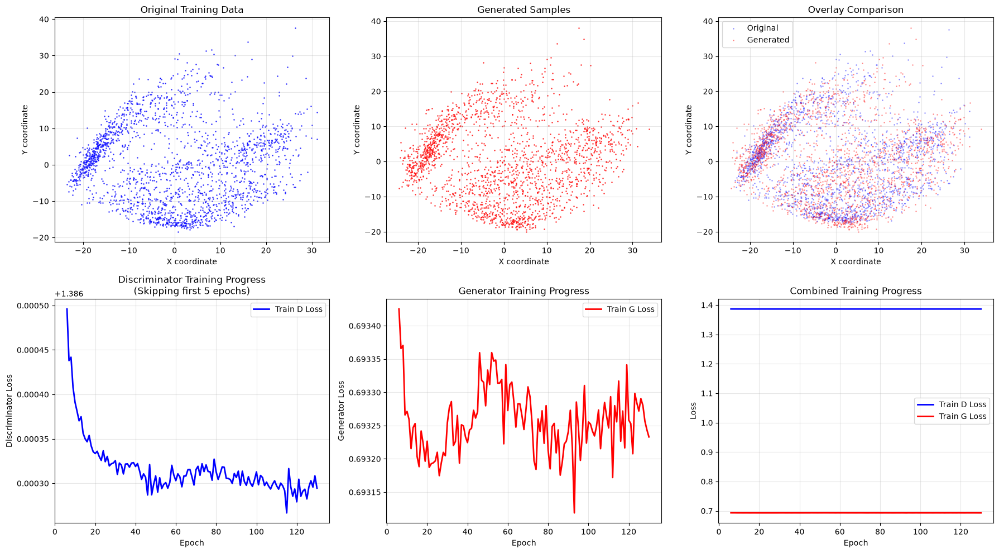

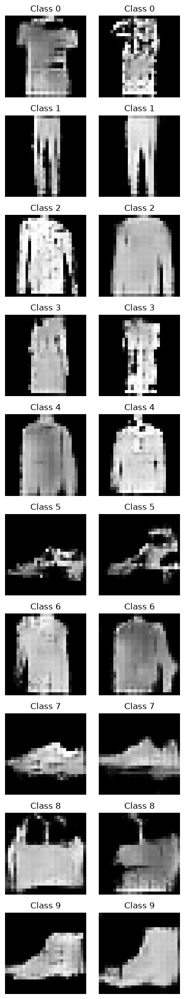

📈 Epoch 130 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3859
   Train G Loss: 0.6932, Val G Loss: 0.6967

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/60000 (0%)]	D_loss: 1.385939	G_loss: 0.692546
Epoch: 131 [6400/60000 (11%)]	D_loss: 1.386302	G_loss: 0.693042
Epoch: 131 [12800/60000 (21%)]	D_loss: 1.386727	G_loss: 0.694869
Epoch: 131 [19200/60000 (32%)]	D_loss: 1.386385	G_loss: 0.691999
Epoch: 131 [25600/60000 (43%)]	D_loss: 1.386365	G_loss: 0.692461
Epoch: 131 [32000/60000 (53%)]	D_loss: 1.386072	G_loss: 0.692878
Epoch: 131 [38400/60000 (64%)]	D_loss: 1.386348	G_loss: 0.693048
Epoch: 131 [44800/60000 (75%)]	D_loss: 1.386218	G_loss: 0.694413
Epoch: 131 [51200/60000 (85%)]	D_loss: 1.386143	G_loss: 0.690503
Epoch: 131 [57600/60000 (96%)]	D_loss: 1.386231	G_loss: 0.693267
====> Epoch: 131 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 131 Val D_loss: 1.3863, Val G_loss: 0.6929
📈 Epoch 131 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

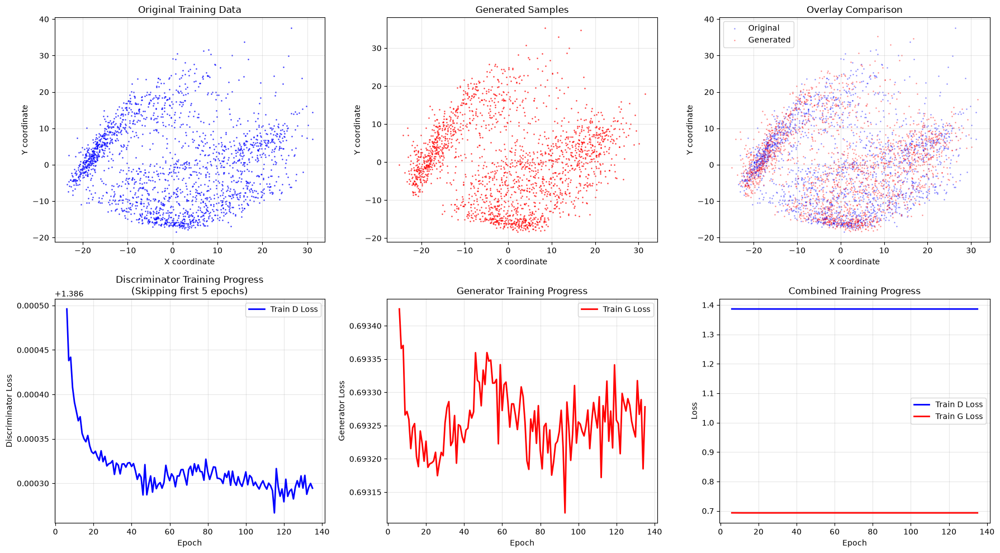

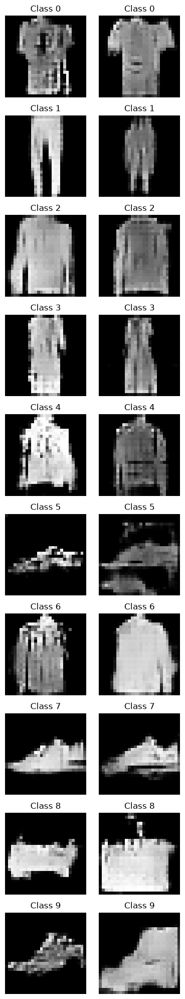

📈 Epoch 135 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6933, Val G Loss: 0.6910

📊 Epoch 136/200
----------------------------------------
Epoch: 136 [0/60000 (0%)]	D_loss: 1.386350	G_loss: 0.691577
Epoch: 136 [6400/60000 (11%)]	D_loss: 1.386437	G_loss: 0.694893
Epoch: 136 [12800/60000 (21%)]	D_loss: 1.386460	G_loss: 0.693227
Epoch: 136 [19200/60000 (32%)]	D_loss: 1.386159	G_loss: 0.694343
Epoch: 136 [25600/60000 (43%)]	D_loss: 1.386123	G_loss: 0.692167
Epoch: 136 [32000/60000 (53%)]	D_loss: 1.386094	G_loss: 0.690953
Epoch: 136 [38400/60000 (64%)]	D_loss: 1.386211	G_loss: 0.693722
Epoch: 136 [44800/60000 (75%)]	D_loss: 1.386115	G_loss: 0.693605
Epoch: 136 [51200/60000 (85%)]	D_loss: 1.386233	G_loss: 0.693542
Epoch: 136 [57600/60000 (96%)]	D_loss: 1.386057	G_loss: 0.692918
====> Epoch: 136 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 136 Val D_loss: 1.3868, Val G_loss: 0.6928
📈 Epoch 136 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3868
   Train

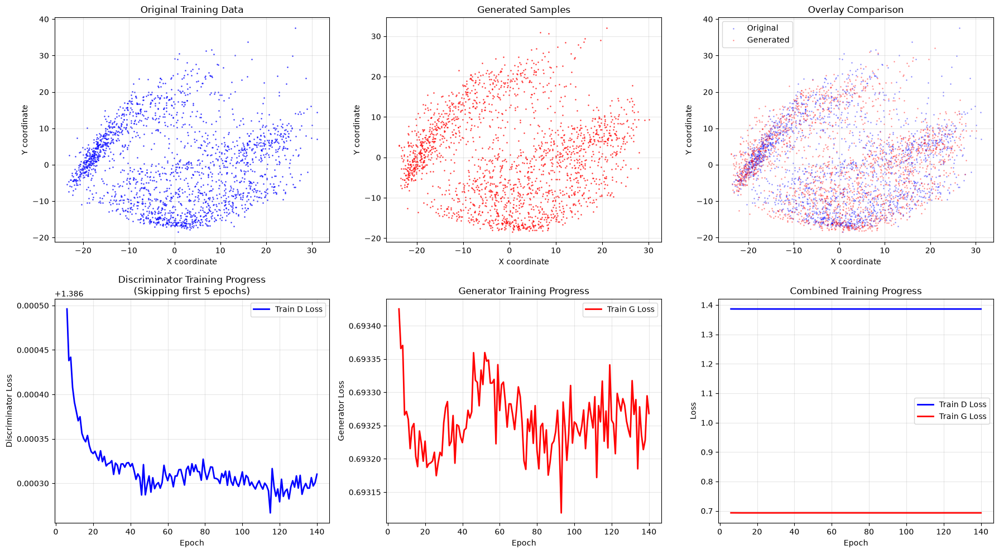

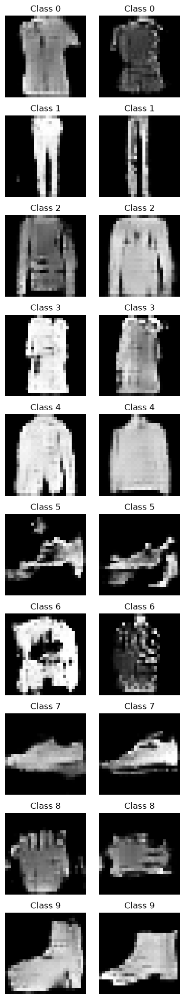

📈 Epoch 140 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6933, Val G Loss: 0.6919

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/60000 (0%)]	D_loss: 1.386328	G_loss: 0.692794
Epoch: 141 [6400/60000 (11%)]	D_loss: 1.386425	G_loss: 0.694003
Epoch: 141 [12800/60000 (21%)]	D_loss: 1.386146	G_loss: 0.695075
Epoch: 141 [19200/60000 (32%)]	D_loss: 1.386163	G_loss: 0.693698
Epoch: 141 [25600/60000 (43%)]	D_loss: 1.386387	G_loss: 0.692798
Epoch: 141 [32000/60000 (53%)]	D_loss: 1.386291	G_loss: 0.695087
Epoch: 141 [38400/60000 (64%)]	D_loss: 1.386082	G_loss: 0.692574
Epoch: 141 [44800/60000 (75%)]	D_loss: 1.386294	G_loss: 0.692531
Epoch: 141 [51200/60000 (85%)]	D_loss: 1.386193	G_loss: 0.693006
Epoch: 141 [57600/60000 (96%)]	D_loss: 1.386386	G_loss: 0.695411
====> Epoch: 141 Train D_loss: 1.3863, Train G_loss: 0.6933
====> Epoch: 141 Val D_loss: 1.3859, Val G_loss: 0.6916
📈 Epoch 141 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3859
   Train

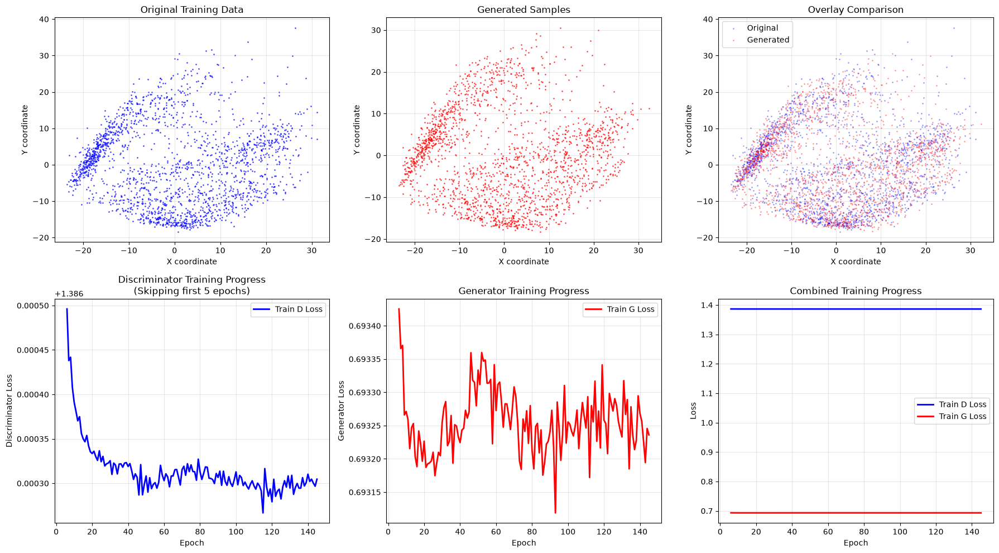

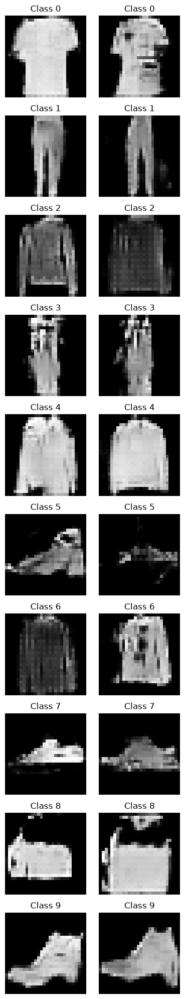

📈 Epoch 145 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6936

📊 Epoch 146/200
----------------------------------------
Epoch: 146 [0/60000 (0%)]	D_loss: 1.386438	G_loss: 0.693411
Epoch: 146 [6400/60000 (11%)]	D_loss: 1.386202	G_loss: 0.693213
Epoch: 146 [12800/60000 (21%)]	D_loss: 1.386267	G_loss: 0.693385
Epoch: 146 [19200/60000 (32%)]	D_loss: 1.386256	G_loss: 0.692425
Epoch: 146 [25600/60000 (43%)]	D_loss: 1.386352	G_loss: 0.692842
Epoch: 146 [32000/60000 (53%)]	D_loss: 1.386582	G_loss: 0.694473
Epoch: 146 [38400/60000 (64%)]	D_loss: 1.386222	G_loss: 0.691502
Epoch: 146 [44800/60000 (75%)]	D_loss: 1.386427	G_loss: 0.693528
Epoch: 146 [51200/60000 (85%)]	D_loss: 1.386265	G_loss: 0.694052
Epoch: 146 [57600/60000 (96%)]	D_loss: 1.386225	G_loss: 0.693404
====> Epoch: 146 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 146 Val D_loss: 1.3864, Val G_loss: 0.6909
📈 Epoch 146 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train

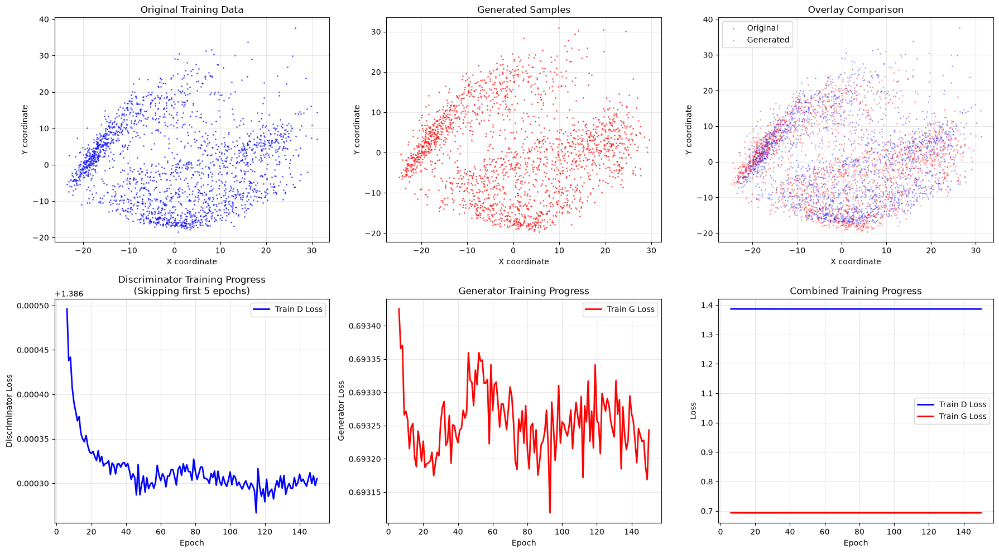

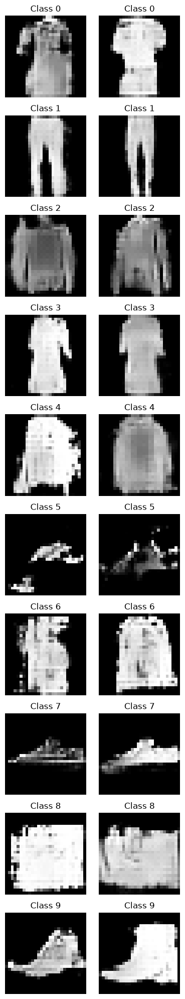

📈 Epoch 150 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3868
   Train G Loss: 0.6932, Val G Loss: 0.6944

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/60000 (0%)]	D_loss: 1.386424	G_loss: 0.692131
Epoch: 151 [6400/60000 (11%)]	D_loss: 1.386587	G_loss: 0.694954
Epoch: 151 [12800/60000 (21%)]	D_loss: 1.386244	G_loss: 0.693743
Epoch: 151 [19200/60000 (32%)]	D_loss: 1.386323	G_loss: 0.693564
Epoch: 151 [25600/60000 (43%)]	D_loss: 1.386501	G_loss: 0.691309
Epoch: 151 [32000/60000 (53%)]	D_loss: 1.386209	G_loss: 0.693519
Epoch: 151 [38400/60000 (64%)]	D_loss: 1.386123	G_loss: 0.693197
Epoch: 151 [44800/60000 (75%)]	D_loss: 1.386333	G_loss: 0.692636
Epoch: 151 [51200/60000 (85%)]	D_loss: 1.386084	G_loss: 0.693062
Epoch: 151 [57600/60000 (96%)]	D_loss: 1.386440	G_loss: 0.693434
====> Epoch: 151 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 151 Val D_loss: 1.3860, Val G_loss: 0.6937
📈 Epoch 151 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3860
   Train

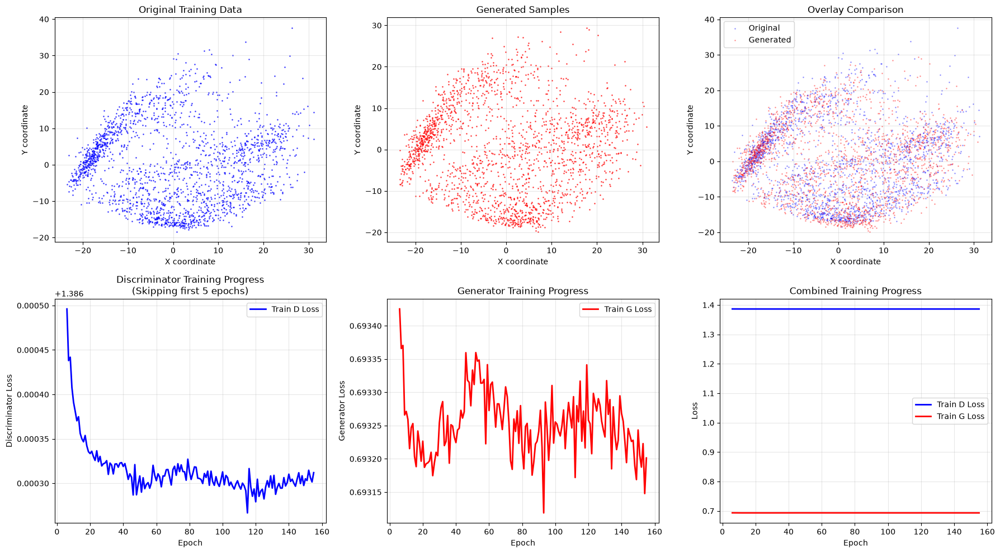

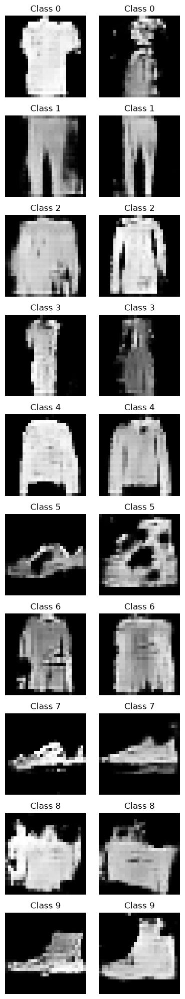

📈 Epoch 155 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3858
   Train G Loss: 0.6932, Val G Loss: 0.6944

📊 Epoch 156/200
----------------------------------------
Epoch: 156 [0/60000 (0%)]	D_loss: 1.386227	G_loss: 0.694603
Epoch: 156 [6400/60000 (11%)]	D_loss: 1.386643	G_loss: 0.692960
Epoch: 156 [12800/60000 (21%)]	D_loss: 1.386310	G_loss: 0.692074
Epoch: 156 [19200/60000 (32%)]	D_loss: 1.386346	G_loss: 0.693237
Epoch: 156 [25600/60000 (43%)]	D_loss: 1.386155	G_loss: 0.694727
Epoch: 156 [32000/60000 (53%)]	D_loss: 1.386420	G_loss: 0.692013
Epoch: 156 [38400/60000 (64%)]	D_loss: 1.386135	G_loss: 0.695297
Epoch: 156 [44800/60000 (75%)]	D_loss: 1.386520	G_loss: 0.692746
Epoch: 156 [51200/60000 (85%)]	D_loss: 1.386060	G_loss: 0.694363
Epoch: 156 [57600/60000 (96%)]	D_loss: 1.386136	G_loss: 0.693981
====> Epoch: 156 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 156 Val D_loss: 1.3866, Val G_loss: 0.6931
📈 Epoch 156 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3866
   Train

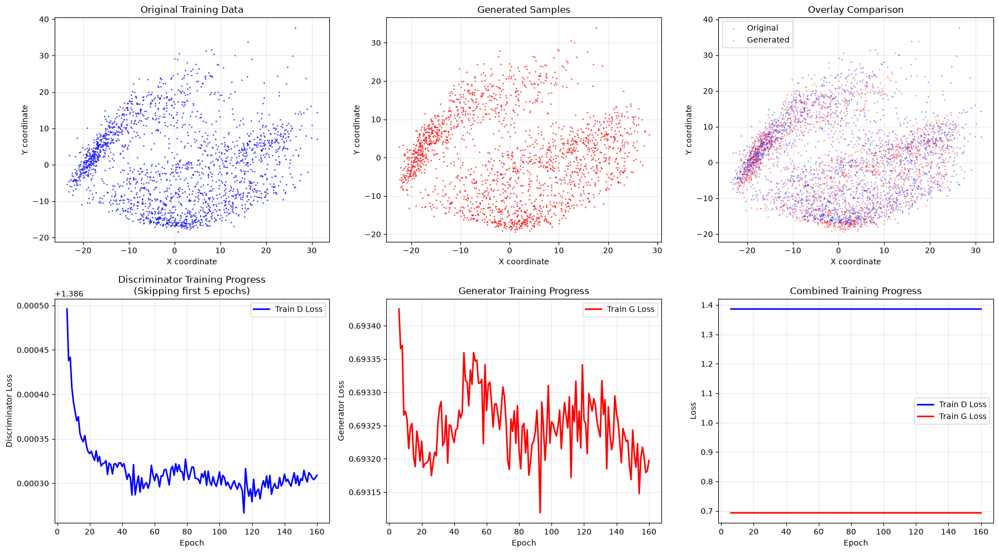

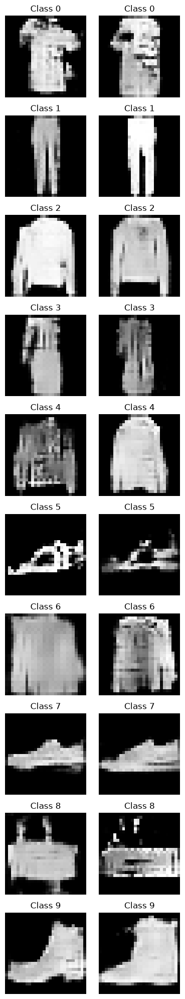

📈 Epoch 160 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6928

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/60000 (0%)]	D_loss: 1.386275	G_loss: 0.691471
Epoch: 161 [6400/60000 (11%)]	D_loss: 1.386359	G_loss: 0.692792
Epoch: 161 [12800/60000 (21%)]	D_loss: 1.386428	G_loss: 0.691370
Epoch: 161 [19200/60000 (32%)]	D_loss: 1.386292	G_loss: 0.694242
Epoch: 161 [25600/60000 (43%)]	D_loss: 1.386458	G_loss: 0.693695
Epoch: 161 [32000/60000 (53%)]	D_loss: 1.386234	G_loss: 0.694167
Epoch: 161 [38400/60000 (64%)]	D_loss: 1.386378	G_loss: 0.692422
Epoch: 161 [44800/60000 (75%)]	D_loss: 1.386329	G_loss: 0.693900
Epoch: 161 [51200/60000 (85%)]	D_loss: 1.386080	G_loss: 0.692751
Epoch: 161 [57600/60000 (96%)]	D_loss: 1.386307	G_loss: 0.693591
====> Epoch: 161 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 161 Val D_loss: 1.3861, Val G_loss: 0.6946
📈 Epoch 161 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train

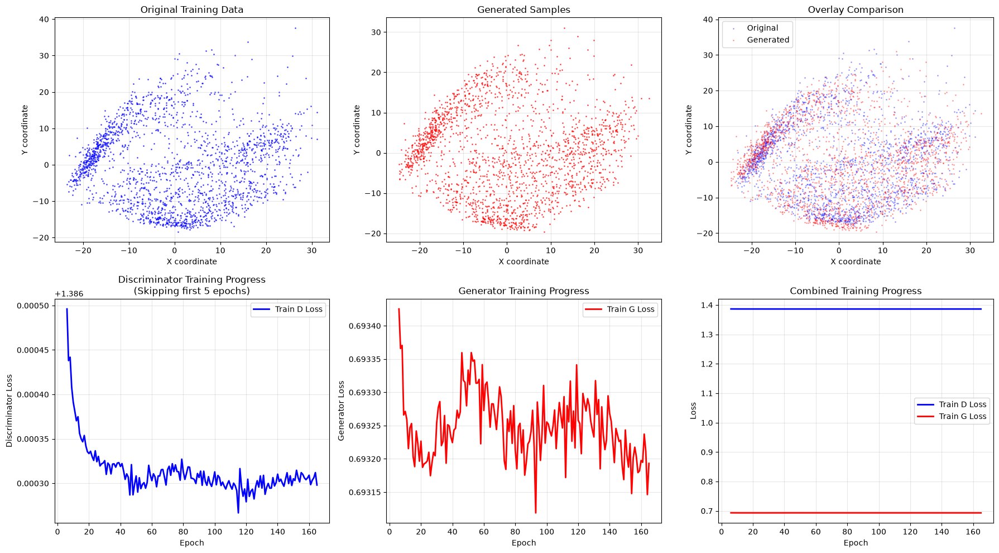

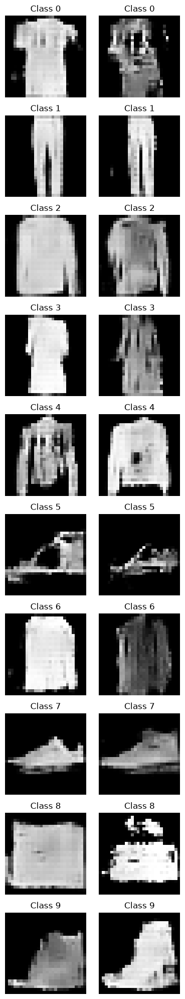

📈 Epoch 165 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3862
   Train G Loss: 0.6932, Val G Loss: 0.6926

📊 Epoch 166/200
----------------------------------------
Epoch: 166 [0/60000 (0%)]	D_loss: 1.386229	G_loss: 0.693071
Epoch: 166 [6400/60000 (11%)]	D_loss: 1.386244	G_loss: 0.693248
Epoch: 166 [12800/60000 (21%)]	D_loss: 1.386418	G_loss: 0.691618
Epoch: 166 [19200/60000 (32%)]	D_loss: 1.386369	G_loss: 0.694664
Epoch: 166 [25600/60000 (43%)]	D_loss: 1.386228	G_loss: 0.693763
Epoch: 166 [32000/60000 (53%)]	D_loss: 1.386153	G_loss: 0.693598
Epoch: 166 [38400/60000 (64%)]	D_loss: 1.386254	G_loss: 0.692380
Epoch: 166 [44800/60000 (75%)]	D_loss: 1.386460	G_loss: 0.690974
Epoch: 166 [51200/60000 (85%)]	D_loss: 1.386258	G_loss: 0.694453
Epoch: 166 [57600/60000 (96%)]	D_loss: 1.386317	G_loss: 0.693719
====> Epoch: 166 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 166 Val D_loss: 1.3863, Val G_loss: 0.6937
📈 Epoch 166 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

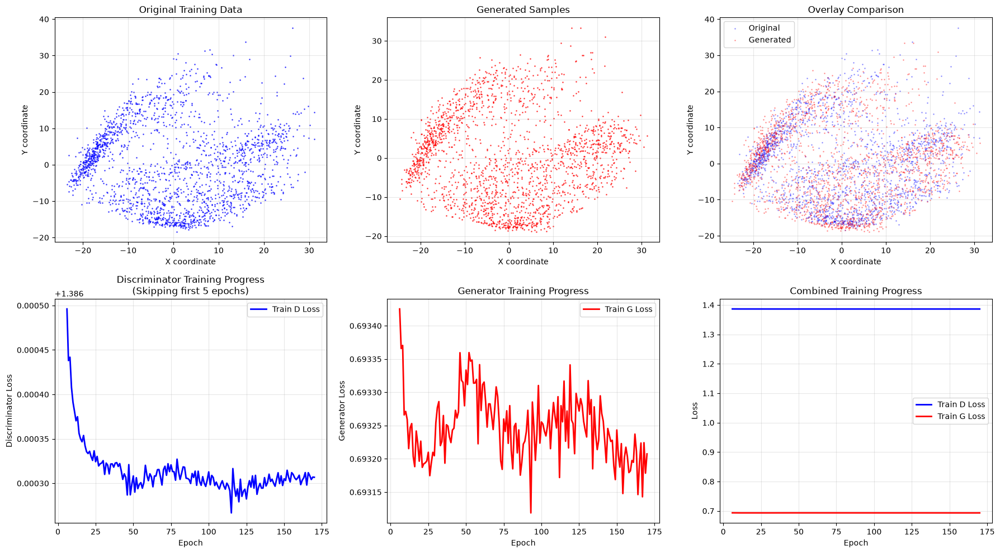

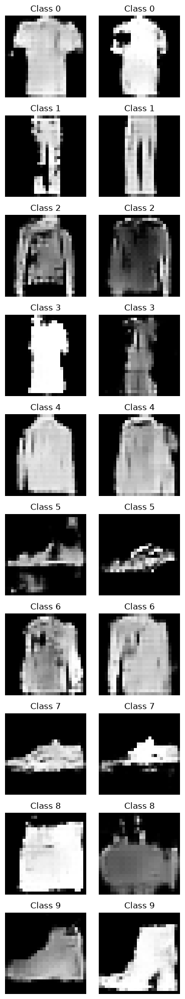

📈 Epoch 170 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6935

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/60000 (0%)]	D_loss: 1.386361	G_loss: 0.693979
Epoch: 171 [6400/60000 (11%)]	D_loss: 1.386484	G_loss: 0.692474
Epoch: 171 [12800/60000 (21%)]	D_loss: 1.386321	G_loss: 0.693370
Epoch: 171 [19200/60000 (32%)]	D_loss: 1.386159	G_loss: 0.693203
Epoch: 171 [25600/60000 (43%)]	D_loss: 1.386198	G_loss: 0.692276
Epoch: 171 [32000/60000 (53%)]	D_loss: 1.386176	G_loss: 0.694419
Epoch: 171 [38400/60000 (64%)]	D_loss: 1.386309	G_loss: 0.692552
Epoch: 171 [44800/60000 (75%)]	D_loss: 1.386187	G_loss: 0.694179
Epoch: 171 [51200/60000 (85%)]	D_loss: 1.386268	G_loss: 0.693306
Epoch: 171 [57600/60000 (96%)]	D_loss: 1.386330	G_loss: 0.693700
====> Epoch: 171 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 171 Val D_loss: 1.3859, Val G_loss: 0.6937
📈 Epoch 171 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3859
   Train

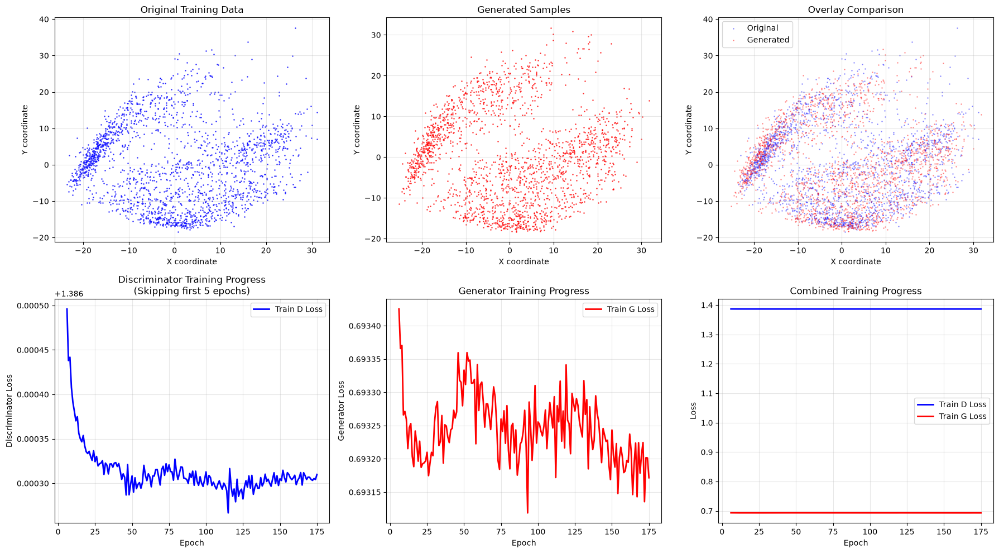

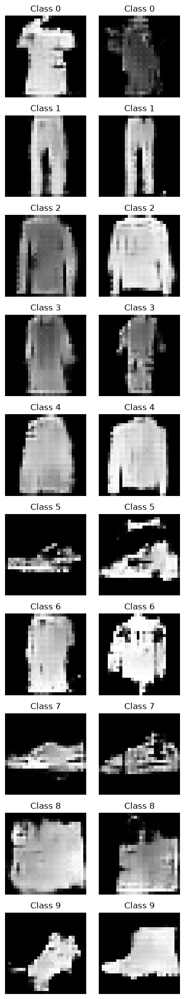

📈 Epoch 175 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6945

📊 Epoch 176/200
----------------------------------------
Epoch: 176 [0/60000 (0%)]	D_loss: 1.386299	G_loss: 0.694027
Epoch: 176 [6400/60000 (11%)]	D_loss: 1.386327	G_loss: 0.693605
Epoch: 176 [12800/60000 (21%)]	D_loss: 1.386540	G_loss: 0.691731
Epoch: 176 [19200/60000 (32%)]	D_loss: 1.386252	G_loss: 0.692392
Epoch: 176 [25600/60000 (43%)]	D_loss: 1.386253	G_loss: 0.692726
Epoch: 176 [32000/60000 (53%)]	D_loss: 1.386282	G_loss: 0.693980
Epoch: 176 [38400/60000 (64%)]	D_loss: 1.386374	G_loss: 0.693031
Epoch: 176 [44800/60000 (75%)]	D_loss: 1.386160	G_loss: 0.693613
Epoch: 176 [51200/60000 (85%)]	D_loss: 1.386362	G_loss: 0.693040
Epoch: 176 [57600/60000 (96%)]	D_loss: 1.386363	G_loss: 0.693348
====> Epoch: 176 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 176 Val D_loss: 1.3863, Val G_loss: 0.6936
📈 Epoch 176 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train

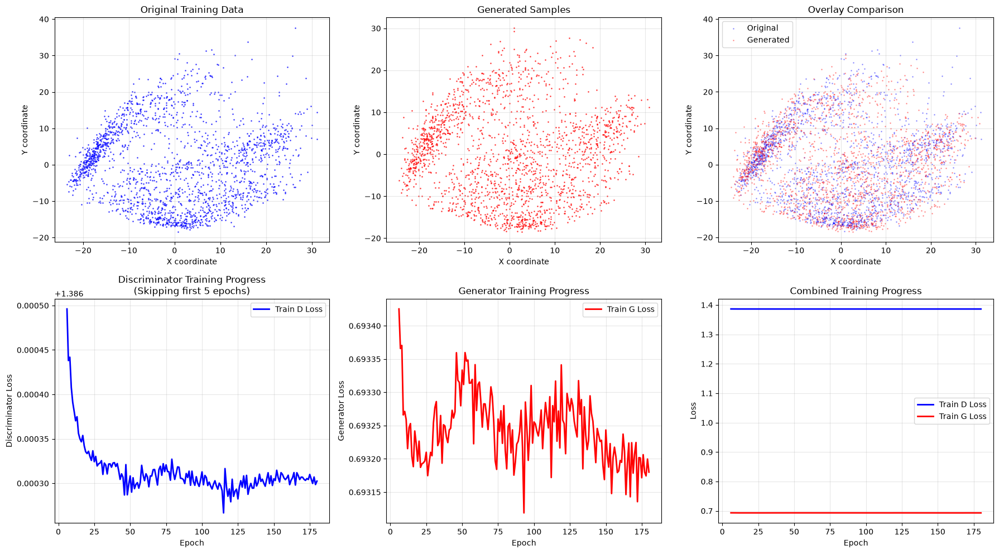

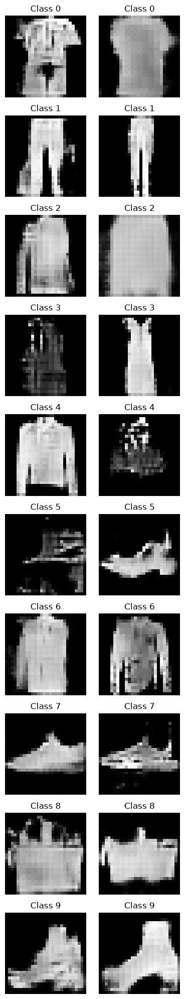

📈 Epoch 180 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3858
   Train G Loss: 0.6932, Val G Loss: 0.6935

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/60000 (0%)]	D_loss: 1.386354	G_loss: 0.692405
Epoch: 181 [6400/60000 (11%)]	D_loss: 1.386335	G_loss: 0.693294
Epoch: 181 [12800/60000 (21%)]	D_loss: 1.386441	G_loss: 0.693869
Epoch: 181 [19200/60000 (32%)]	D_loss: 1.386225	G_loss: 0.692051
Epoch: 181 [25600/60000 (43%)]	D_loss: 1.386400	G_loss: 0.693800
Epoch: 181 [32000/60000 (53%)]	D_loss: 1.386256	G_loss: 0.693287
Epoch: 181 [38400/60000 (64%)]	D_loss: 1.386259	G_loss: 0.694264
Epoch: 181 [44800/60000 (75%)]	D_loss: 1.386545	G_loss: 0.692948
Epoch: 181 [51200/60000 (85%)]	D_loss: 1.386315	G_loss: 0.693843
Epoch: 181 [57600/60000 (96%)]	D_loss: 1.386281	G_loss: 0.692347
====> Epoch: 181 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 181 Val D_loss: 1.3866, Val G_loss: 0.6913
📈 Epoch 181 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3866
   Train

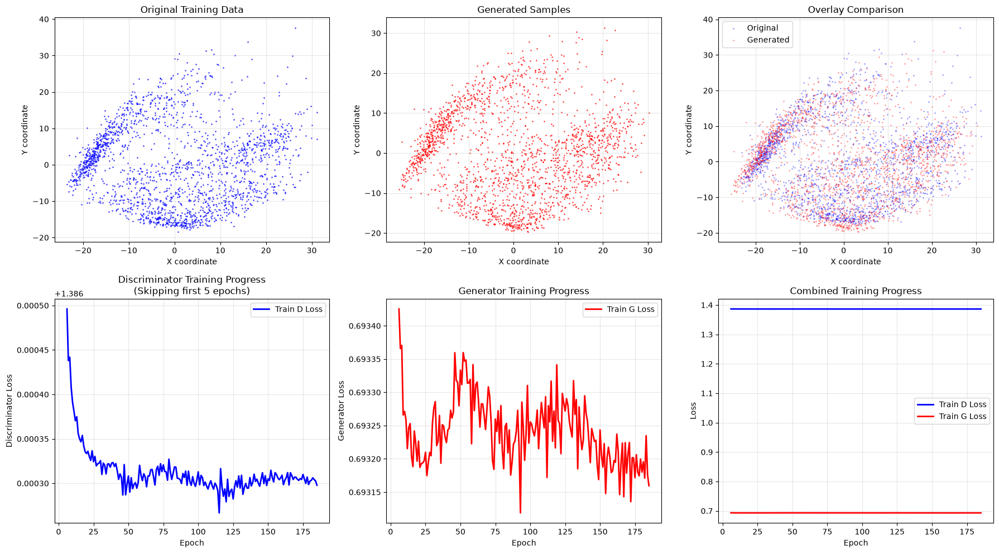

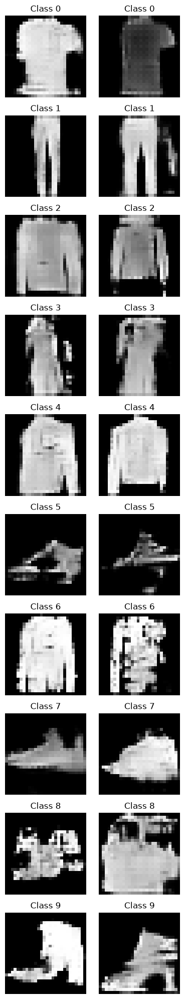

📈 Epoch 185 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3863
   Train G Loss: 0.6932, Val G Loss: 0.6927

📊 Epoch 186/200
----------------------------------------
Epoch: 186 [0/60000 (0%)]	D_loss: 1.386468	G_loss: 0.693359
Epoch: 186 [6400/60000 (11%)]	D_loss: 1.386420	G_loss: 0.692845
Epoch: 186 [12800/60000 (21%)]	D_loss: 1.386147	G_loss: 0.693310
Epoch: 186 [19200/60000 (32%)]	D_loss: 1.386433	G_loss: 0.692383
Epoch: 186 [25600/60000 (43%)]	D_loss: 1.386207	G_loss: 0.693768
Epoch: 186 [32000/60000 (53%)]	D_loss: 1.386274	G_loss: 0.693649
Epoch: 186 [38400/60000 (64%)]	D_loss: 1.386160	G_loss: 0.692661
Epoch: 186 [44800/60000 (75%)]	D_loss: 1.386296	G_loss: 0.693197
Epoch: 186 [51200/60000 (85%)]	D_loss: 1.386501	G_loss: 0.693398
Epoch: 186 [57600/60000 (96%)]	D_loss: 1.386187	G_loss: 0.693079
====> Epoch: 186 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 186 Val D_loss: 1.3864, Val G_loss: 0.6927
📈 Epoch 186 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train

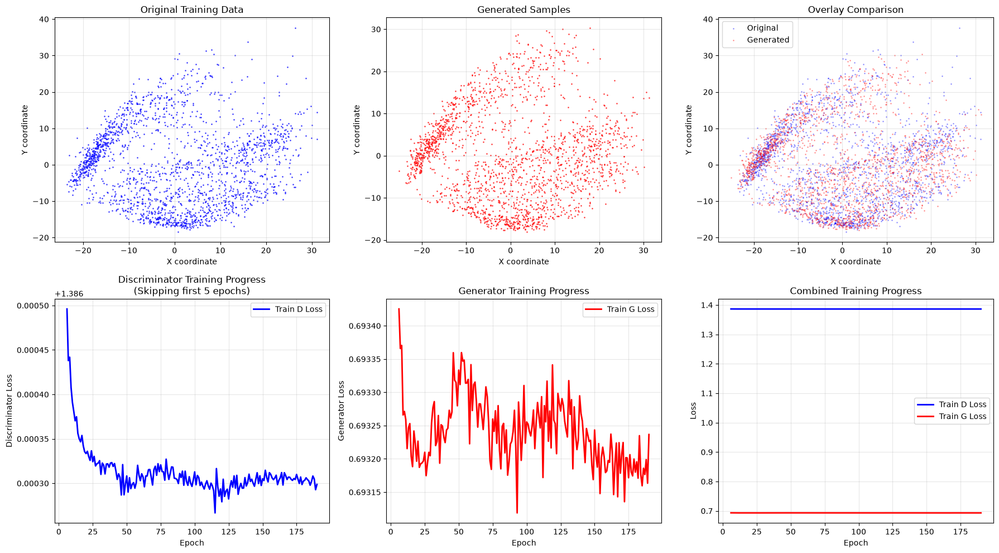

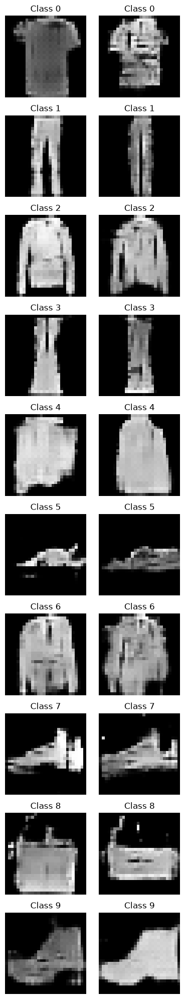

📈 Epoch 190 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train G Loss: 0.6932, Val G Loss: 0.6928

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/60000 (0%)]	D_loss: 1.386338	G_loss: 0.693158
Epoch: 191 [6400/60000 (11%)]	D_loss: 1.386106	G_loss: 0.692972
Epoch: 191 [12800/60000 (21%)]	D_loss: 1.386328	G_loss: 0.694023
Epoch: 191 [19200/60000 (32%)]	D_loss: 1.386300	G_loss: 0.692662
Epoch: 191 [25600/60000 (43%)]	D_loss: 1.386286	G_loss: 0.693815
Epoch: 191 [32000/60000 (53%)]	D_loss: 1.386239	G_loss: 0.692954
Epoch: 191 [38400/60000 (64%)]	D_loss: 1.386211	G_loss: 0.692998
Epoch: 191 [44800/60000 (75%)]	D_loss: 1.385838	G_loss: 0.693315
Epoch: 191 [51200/60000 (85%)]	D_loss: 1.386322	G_loss: 0.692567
Epoch: 191 [57600/60000 (96%)]	D_loss: 1.386254	G_loss: 0.693330
====> Epoch: 191 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 191 Val D_loss: 1.3864, Val G_loss: 0.6940
📈 Epoch 191 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3864
   Train

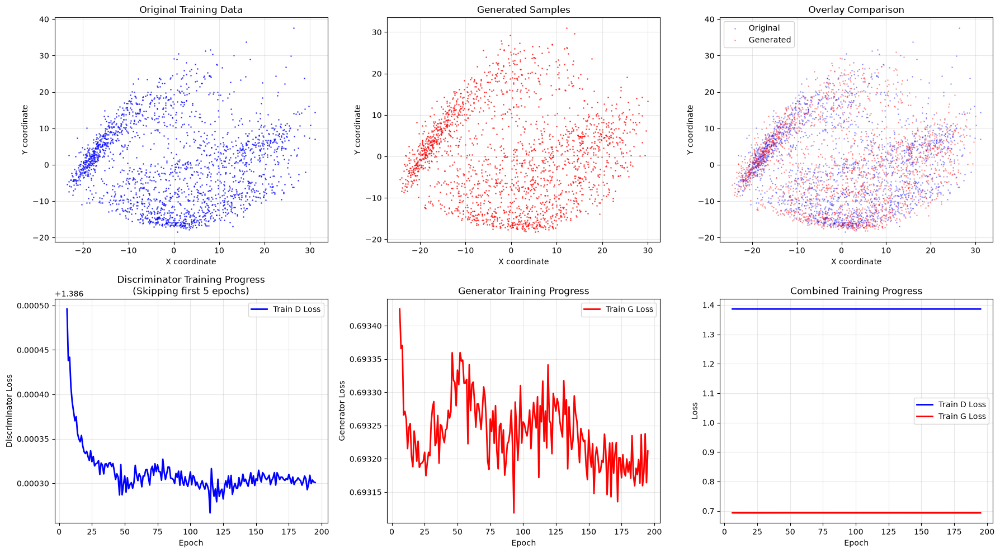

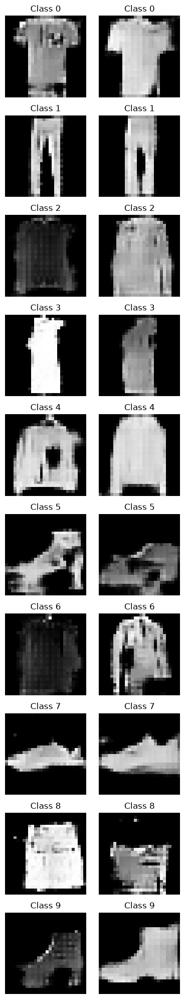

📈 Epoch 195 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3861
   Train G Loss: 0.6932, Val G Loss: 0.6942

📊 Epoch 196/200
----------------------------------------
Epoch: 196 [0/60000 (0%)]	D_loss: 1.386273	G_loss: 0.693381
Epoch: 196 [6400/60000 (11%)]	D_loss: 1.386302	G_loss: 0.692958
Epoch: 196 [12800/60000 (21%)]	D_loss: 1.386435	G_loss: 0.693160
Epoch: 196 [19200/60000 (32%)]	D_loss: 1.386236	G_loss: 0.693843
Epoch: 196 [25600/60000 (43%)]	D_loss: 1.386246	G_loss: 0.693060
Epoch: 196 [32000/60000 (53%)]	D_loss: 1.386294	G_loss: 0.693587
Epoch: 196 [38400/60000 (64%)]	D_loss: 1.386335	G_loss: 0.693524
Epoch: 196 [44800/60000 (75%)]	D_loss: 1.386304	G_loss: 0.692871
Epoch: 196 [51200/60000 (85%)]	D_loss: 1.386345	G_loss: 0.694157
Epoch: 196 [57600/60000 (96%)]	D_loss: 1.386125	G_loss: 0.694000
====> Epoch: 196 Train D_loss: 1.3863, Train G_loss: 0.6932
====> Epoch: 196 Val D_loss: 1.3868, Val G_loss: 0.6924
📈 Epoch 196 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3868
   Train

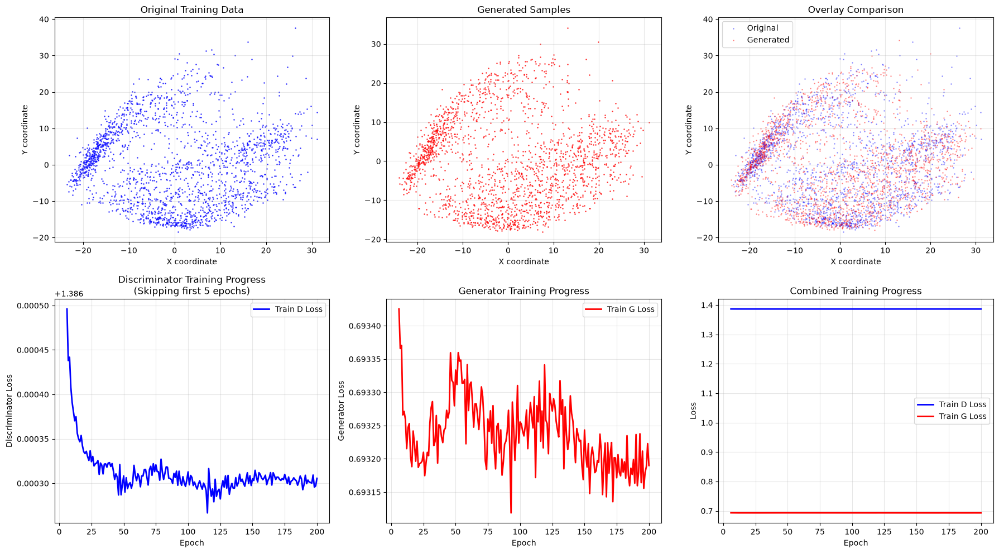

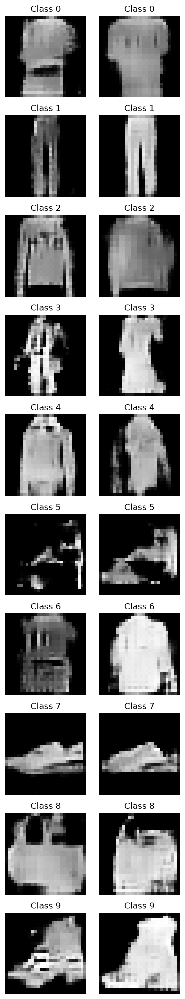

📈 Epoch 200 Summary:
   Train D Loss: 1.3863, Val D Loss: 1.3860
   Train G Loss: 0.6932, Val G Loss: 0.6927

🎉 Training completed!

🎨 Final comprehensive visualization:


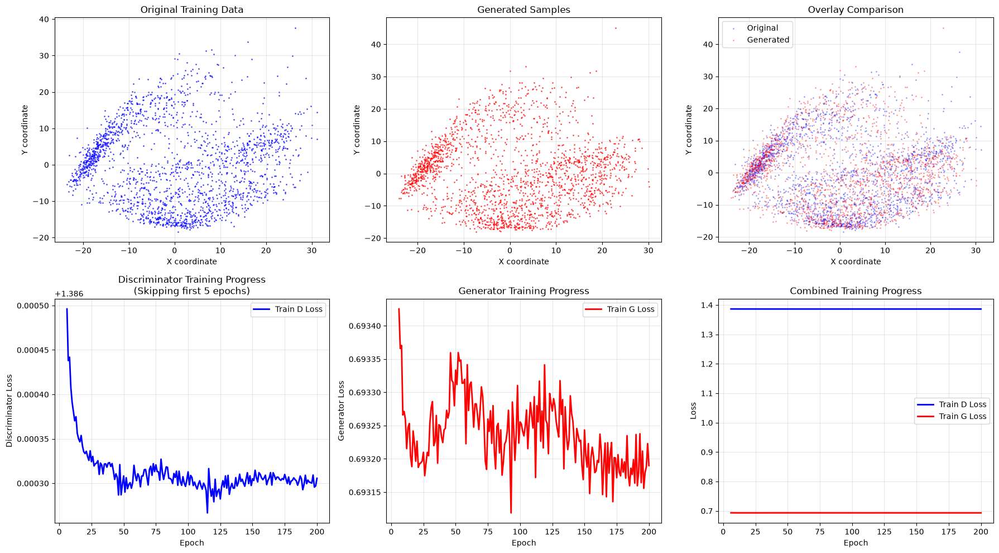

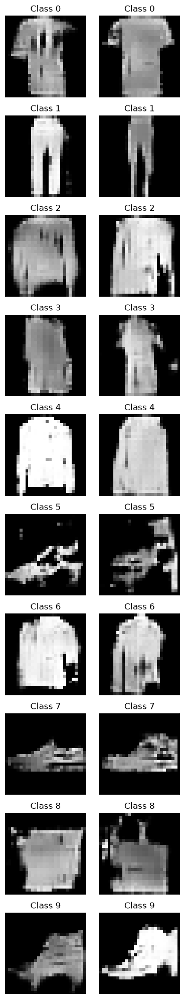

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


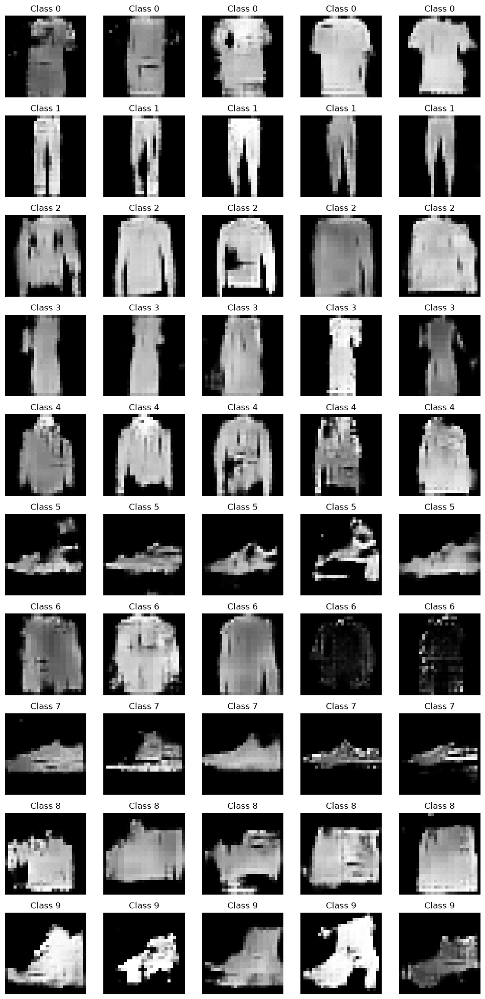

Real data confidence with matching classes: 0.500
Fake data confidence with requested classes: 0.500


In [15]:
TARGET_CLASSES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
SAMPLES_PER_CLASS = 5

visualize_class_samples(TARGET_CLASSES, samples_per_class=SAMPLES_PER_CLASS)

generated_sevens = generate_samples(20, classes=7)
generated_digits = generate_samples(len(TARGET_CLASSES), classes=TARGET_CLASSES)

generator.eval()
discriminator.eval()
with torch.no_grad():
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_classes = train_data.targets[:100].to(device)
    real_pred = discriminator(real_batch, real_classes).mean().item()

    fake_classes = torch.tensor(TARGET_CLASSES, device=device).repeat(100)[:100]
    noise = torch.randn(100, NOISE_DIM, device=device)
    fake_batch = generator(noise, fake_classes)
    fake_pred = discriminator(fake_batch, fake_classes).mean().item()

print(f'Real data confidence with matching classes: {real_pred:.3f}')
print(f'Fake data confidence with requested classes: {fake_pred:.3f}')
